# **PHASE 1: BỘ PHÂN LỚP XÁC SUẤT VÀ TUYẾN TÍNH (NAÏVE BAYES & LOGISTIC REGRESSION)**

---
## **PHẦN 0: KHỞI TẠO THƯ VIỆN VÀ THIẾT LẬP MÔI TRƯỜNG**

Khởi tạo các thư viện tính toán khoa học cơ bản (`numpy`, `pandas`, `matplotlib.pyplot`, `time`, `os`). Cố định hạt giống ngẫu nhiên `SEED = 42` để đảm bảo tính tái lập 100% của mọi phép tính thống kê. Thư viện `scikit-learn` chỉ được nạp vào nhằm mục đích đo đạc độ đo đánh giá và đối chiếu kiểm chứng.

In [1]:
import os
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    display = print

# Chuyen thu muc lam viec ve goc du an neu dang o plan/
if os.path.basename(os.getcwd()) == "plan":
    os.chdir("..")
print("Thu muc lam viec:", os.getcwd())

# Tạo sẵn các thư mục lưu trữ artifact, figures, results bắt buộc
os.makedirs("results", exist_ok=True)
os.makedirs("artifacts", exist_ok=True)
os.makedirs("figures", exist_ok=True)

from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)

print("Thiết lập môi trường thành công. Cố định SEED =", SEED)

Thu muc lam viec: c:\Users\Lenovo\Downloads\Pattern-Recognition
Thiết lập môi trường thành công. Cố định SEED = 42


---
## **PHẦN 1: NẠP DỮ LIỆU ĐÃ TIỀN XỬ LÝ TỪ PHASE 0**

Nạp tập dữ liệu MNIST đã chuẩn hóa được xuất ra từ `phase_00_mnist_data_preprocessing.ipynb` đặt tại `data/processed/mnist_processed.npz`. 
Tập dữ liệu bao gồm:
* `X_train`, `y_train`: 50.000 mẫu huấn luyện chuẩn hoá Z-score (MEAN, STD chỉ tính trên train).
* `X_val`, `y_val`: 10.000 mẫu validation dùng tinh chỉnh siêu tham số.
* `X_test`, `y_test`: 10.000 mẫu kiểm thử độc lập chỉ dùng đánh giá cuối cùng.
* `X_train_minmax`, `X_val_minmax`, `X_test_minmax`: Dạng biểu diễn cường độ $[0, 1]$ không âm dành cho Multinomial Naïve Bayes.

In [2]:
DATA_PATH = "./data/processed/mnist_processed.npz"

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f"Không tìm thấy file {DATA_PATH}. Vui lòng chạy phase0_preprocessing_and_EDA.ipynb trước!")

data = np.load(DATA_PATH)

X_train = data["X_train"]
y_train = data["y_train"]
X_val   = data["X_val"]
y_val   = data["y_val"]
X_test  = data["X_test"]
y_test  = data["y_test"]

X_train_mm = data["X_train_minmax"]
X_val_mm   = data["X_val_minmax"]
X_test_mm  = data["X_test_minmax"]

MEAN = float(data["MEAN"])
STD  = float(data["STD"])

print("Nạp dữ liệu thành công từ data/processed/mnist_processed.npz:")
print(f"  Tập Train: X = {X_train.shape}, y = {y_train.shape} (Phân phối nhãn: {np.bincount(y_train).tolist()})")
print(f"  Tập Val:   X = {X_val.shape},   y = {y_val.shape}")
print(f"  Tập Test:  X = {X_test.shape},  y = {y_test.shape}")
print(f"  Thông số Z-score: MEAN = {MEAN:.4f}, STD = {STD:.4f}")

Nạp dữ liệu thành công từ data/processed/mnist_processed.npz:
  Tập Train: X = (50000, 784), y = (50000,) (Phân phối nhãn: [4923, 5613, 4958, 5093, 4863, 4546, 4933, 5204, 4882, 4985])
  Tập Val:   X = (10000, 784),   y = (10000,)
  Tập Test:  X = (10000, 784),  y = (10000,)
  Thông số Z-score: MEAN = 0.1307, STD = 0.3082


---
## **PHẦN 2: XÂY DỰNG LỚP NAÏVE BAYES TỔNG QUÁT (FROM SCRATCH)**

### **2.1. Cơ sở lý thuyết của Quy tắc Quyết định Bayes (Bayes Decision Rule)**
Theo định lý Bayes, xác suất hậu nghiệm (posterior probability) của lớp $C_k$ khi quan sát vector đặc trưng $\mathbf{x} = (x_1, x_2, \dots, x_D)^T \in \mathbb{R}^D$ là:
$$P(C_k \mid \mathbf{x}) = \frac{P(\mathbf{x} \mid C_k) P(C_k)}{P(\mathbf{x})}$$

Trong đó:
* $P(C_k)$ là **xác suất tiên nghiệm (prior)** của lớp $C_k$, ước lượng bằng tần suất xuất hiện của lớp trong tập huấn luyện:
  $$P(C_k) = \frac{N_k}{N}$$
* $P(\mathbf{x} \mid C_k)$ là **hàm hợp lý (likelihood)** biểu diễn mật độ xác suất sinh ra vector $\mathbf{x}$ từ lớp $C_k$.
* Mẫu số $P(\mathbf{x}) = \sum_j P(\mathbf{x} \mid C_j) P(C_j)$ là hằng số chuẩn hoá đối với mọi lớp $C_k$.

### **2.2. Giả định "Ngây thơ" (Naïve Bayes Assumption) và Không gian Logarit**
Naïve Bayes đưa ra giả định rằng tất cả các đặc trưng $x_1, \dots, x_D$ độc lập có điều kiện với nhau khi biết lớp $C_k$:
$$P(\mathbf{x} \mid C_k) = \prod_{i=1}^D P(x_i \mid C_k)$$

Để tránh hiện tượng tràn số dưới (arithmetic underflow) khi nhân liên tiếp 784 giá trị xác suất nhỏ hơn 1, ta chuyển toàn bộ sang không gian logarit:
$$\log P(C_k \mid \mathbf{x}) \propto \log P(C_k) + \sum_{i=1}^D \log P(x_i \mid C_k)$$

Nhãn dự đoán là lớp có điểm số xác suất hậu nghiệm lớn nhất:
$$\hat{y} = \arg\max_{k} \left[ \log P(C_k) + \sum_{i=1}^D \log P(x_i \mid C_k) \right]$$

In [3]:
class NaiveBayes:
    # Lớp Naive Bayes tổng quát thuần NumPy (From Scratch) - bám sát chuẩn Lab 02.
    def __init__(self, log_pdf, var_smoothing=1e-9):
        self.log_pdf = log_pdf
        self.var_smoothing = var_smoothing

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.classes = np.unique(y)
        n_classes = len(self.classes)

        self.mean = np.zeros((n_classes, n_features))
        self.var = np.zeros((n_classes, n_features))
        self.prior = np.zeros(n_classes)

        # Lượng làm mịn epsilon tránh phương sai bằng 0 (tương tự var_smoothing của scikit-learn)
        eps = self.var_smoothing * X.var(axis=0).max()

        for idx, c in enumerate(self.classes):
            X_c = X[y == c]
            self.mean[idx] = X_c.mean(axis=0)
            self.var[idx] = X_c.var(axis=0) + eps
            self.prior[idx] = X_c.shape[0] / n_samples

        return self

    def predict(self, X):
        scores = []
        for idx in range(len(self.classes)):
            # Tính tổng log-likelihood trên tất cả 784 đặc trưng
            log_likelihood = np.sum(
                self.log_pdf(X, self.mean[idx], self.var[idx]), axis=1
            )
            # log P(C_k | x) tỷ lệ thuận với log P(C_k) + sum(log P(x_i | C_k))
            scores.append(log_likelihood + np.log(self.prior[idx]))

        # Chọn lớp có điểm số log-posterior cao nhất cho mỗi mẫu
        return self.classes[np.argmax(scores, axis=0)]

---
## **PHẦN 3: BIẾN THỂ GAUSSIAN NAÏVE BAYES**

### **3.1. Bản chất toán học của Gaussian Log-Likelihood**
Mỗi đặc trưng $x_i$ trong lớp $C_k$ được giả định tuân theo phân phối chuẩn một chiều (1D Gaussian):
$$P(x_i \mid C_k) = \frac{1}{\sqrt{2\pi \sigma_{ik}^2}} \exp\left( -\frac{(x_i - \mu_{ik})^2}{2\sigma_{ik}^2} \right)$$

Lấy logarit tự nhiên hai vế:
$$\log P(x_i \mid C_k) = -\frac{1}{2}\log(2\pi \sigma_{ik}^2) - \frac{(x_i - \mu_{ik})^2}{2\sigma_{ik}^2}$$

* **Cụm 1: $-\frac{1}{2}\log(2\pi \sigma_{ik}^2)$** đóng vai trò là số hạng phạt độ phân tán (variance penalty). Đặc trưng có phương sai càng lớn thì độ bất định càng cao, đóng góp thông tin phân loại càng thấp.
* **Cụm 2: $-\frac{(x_i - \mu_{ik})^2}{2\sigma_{ik}^2}$** là khoảng cách chuẩn hoá Mahalanobis 1D. Đo đạc mức độ lệch của mẫu $x_i$ so với kỳ vọng $\mu_{ik}$ của lớp.

In [4]:
def gaussian_log_pdf(X, mean, var):
    # log N(x_i | mean_i, var_i), shape (n_samples, n_features).
    # X: (n_samples, n_features), mean, var: (n_features,) -> NumPy broadcasting
    return -0.5 * np.log(2 * np.pi * var) - (X - mean) ** 2 / (2 * var)

### **3.2. Kiểm tra hàm `gaussian_log_pdf`**
Thực hiện kiểm tra tính đúng đắn về mặt giải tích của hàm `gaussian_log_pdf` trên dữ liệu ngẫu nhiên đối chiếu với thư viện `scipy.stats.norm.logpdf`.

In [5]:
from scipy import stats

# check (do not edit - chuẩn Lab 02)
X_chk, m_chk, v_chk = np.random.randn(20, 4), np.random.randn(4), np.random.rand(4) + 0.1
assert np.allclose(gaussian_log_pdf(X_chk, m_chk, v_chk), stats.norm.logpdf(X_chk, m_chk, np.sqrt(v_chk)))
print(" Kiểm tra hàm gaussian_log_pdf thành công! Khớp 100% với scipy.stats.norm.logpdf.")

 Kiểm tra hàm gaussian_log_pdf thành công! Khớp 100% với scipy.stats.norm.logpdf.


### **3.3. Huấn luyện mô hình Gaussian Naïve Bayes Baseline**
Khởi tạo và huấn luyện mô hình Gaussian Naïve Bayes trên 50.000 mẫu tập Train. Đo lường chính xác thời gian huấn luyện.

In [6]:
t0 = time.perf_counter()
model_gnb = NaiveBayes(log_pdf=gaussian_log_pdf, var_smoothing=1e-9)
model_gnb.fit(X_train, y_train)
gnb_fit_time = time.perf_counter() - t0

print(f"Huấn luyện GaussianNB (From Scratch) hoàn tất trong: {gnb_fit_time:.4f} giây")
print("1. Danh sách các lớp nhận dạng:    ", model_gnb.classes.tolist())
print("2. Xác suất tiên nghiệm (prior):    ", np.round(model_gnb.prior, 4).tolist())
print("3. Kích thước ma trận trung bình:  ", model_gnb.mean.shape)
print("4. Kích thước ma trận phương sai:  ", model_gnb.var.shape)

Huấn luyện GaussianNB (From Scratch) hoàn tất trong: 0.2596 giây
1. Danh sách các lớp nhận dạng:     [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
2. Xác suất tiên nghiệm (prior):     [0.0985, 0.1123, 0.0992, 0.1019, 0.0973, 0.0909, 0.0987, 0.1041, 0.0976, 0.0997]
3. Kích thước ma trận trung bình:   (10, 784)
4. Kích thước ma trận phương sai:   (10, 784)


### **3.4. Trực quan hoá tham số học được: "Ảnh nguyên mẫu" ($\mu$) và Bản đồ phương sai ($\sigma^2$)**
* **Ảnh trung bình ($\mu_{k}$):** Thể hiện hình thái trung bình đặc trưng (prototype) của chữ số $k$ trong tập dữ liệu.
* **Bản đồ phương sai ($\sigma_{k}^2$):** Thể hiện mức độ biến động nét chữ của người viết. Các pixel ở giữa nét chữ có phương sai cao do phong cách viết đa dạng; các pixel vùng biên và góc có phương sai tiệm cận 0 do luôn là nền đen.

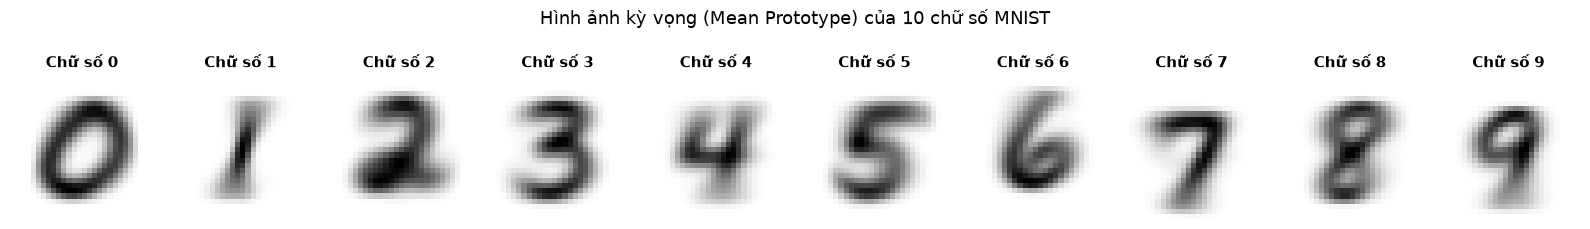

Đã lưu biểu đồ: figures/phase1_02_gaussian_mean_prototypes.png


In [7]:
# Trực quan hoá 10 vector kỳ vọng (mean) tương ứng 10 chữ số
fig, axes = plt.subplots(1, 10, figsize=(16, 2.2))
for k in range(10):
    img_mean = (model_gnb.mean[k] * STD + MEAN).reshape(28, 28)
    axes[k].imshow(img_mean, cmap="gray_r")
    axes[k].set_title(f"Chữ số {k}", fontsize=11, fontweight="bold")
    axes[k].axis("off")

plt.suptitle("Hình ảnh kỳ vọng (Mean Prototype) của 10 chữ số MNIST", fontsize=13, y=1.05)
plt.tight_layout()
plt.savefig("figures/phase1_02_gaussian_mean_prototypes.png", dpi=150, bbox_inches="tight")
plt.show()
print("Đã lưu biểu đồ: figures/phase1_02_gaussian_mean_prototypes.png")

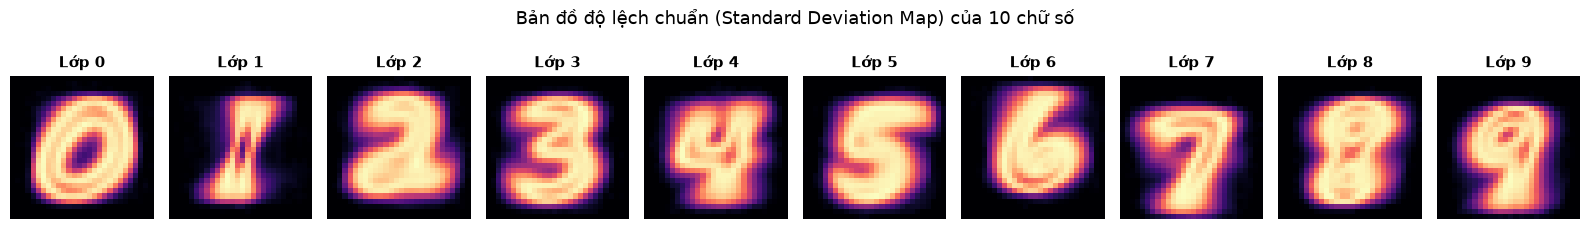

Đã lưu biểu đồ: figures/phase1_03_gaussian_std_maps.png


In [8]:
# Trực quan hoá bản đồ độ lệch chuẩn (Std map) của 10 chữ số
fig, axes = plt.subplots(1, 10, figsize=(16, 2.2))
for k in range(10):
    img_std = (np.sqrt(model_gnb.var[k]) * STD).reshape(28, 28)
    im = axes[k].imshow(img_std, cmap="magma")
    axes[k].set_title(f"Lớp {k}", fontsize=11, fontweight="bold")
    axes[k].axis("off")

plt.suptitle("Bản đồ độ lệch chuẩn (Standard Deviation Map) của 10 chữ số", fontsize=13, y=1.05)
plt.tight_layout()
plt.savefig("figures/phase1_03_gaussian_std_maps.png", dpi=150, bbox_inches="tight")
plt.show()
print("Đã lưu biểu đồ: figures/phase1_03_gaussian_std_maps.png")

---
## **PHẦN 4: TINH CHỈNH SIÊU THAM SỐ LÀM MỊN PHƯƠNG SAI TRÊN TẬP VALIDATION**

### **4.1. Bản chất khoa học của Variance Smoothing ($\epsilon$)**
Trong bộ dữ liệu ảnh MNIST, các pixel ở góc và rìa bức ảnh hầu như luôn có cường độ bằng 0 cho mọi mẫu viết tay. Do đó, phương sai thực nghiệm của các pixel này xấp xỉ bằng $0$ ($\sigma_{ik}^2 \approx 0$).
Nếu không làm mịn:
1. Số hạng chia cho phương sai $-\frac{(x_i - \mu_{ik})^2}{2\sigma_{ik}^2}$ sẽ gặp lỗi chia cho 0 hoặc phát nổ số học.
2. Số hạng logarit $-\frac{1}{2}\log(2\pi \sigma_{ik}^2) \to +\infty$, khiến một vài pixel nền tĩnh chi phối áp đảo toàn bộ điểm số xác suất hậu nghiệm!

Do đó, kỹ thuật **Variance Smoothing** bổ sung một đại lượng $\epsilon = \text{var\_smoothing} \times \max(\text{Var}(X))$ vào phương sai của tất cả các đặc trưng.
Ta tiến hành khảo sát sự biến thiên của độ chính xác trên tập Validation theo dải giá trị:
$$\text{var\_smoothing} \in [10^{-9}, 10^{-7}, 10^{-5}, 10^{-3}, 10^{-2}, 10^{-1}, 1.0]$$

In [9]:
candidate_smoothings = [1e-9, 1e-7, 1e-5, 1e-3, 1e-2, 5e-2, 1e-1, 5e-1, 1.0]
val_accuracies = []
train_accuracies = []

for vs in candidate_smoothings:
    model_temp = NaiveBayes(log_pdf=gaussian_log_pdf, var_smoothing=vs).fit(X_train, y_train)
    
    # Dự đoán trên val
    y_val_pred = model_temp.predict(X_val)
    acc_v = accuracy_score(y_val, y_val_pred)
    val_accuracies.append(acc_v)
    
    # Dự đoán trên mẫu train (5000 mẫu để tiết kiệm thời gian)
    y_tr_pred = model_temp.predict(X_train[:5000])
    acc_t = accuracy_score(y_train[:5000], y_tr_pred)
    train_accuracies.append(acc_t)
    
    print(f"var_smoothing = {vs:<8} | Train Acc (5k): {acc_t:.4f} | Val Acc: {acc_v:.4f}")

best_idx = int(np.argmax(val_accuracies))
best_var_smoothing = candidate_smoothings[best_idx]
print(f"\n=> Siêu tham số tối ưu nhất trên Validation: var_smoothing = {best_var_smoothing} (Val Accuracy = {val_accuracies[best_idx]:.4f})")

var_smoothing = 1e-09    | Train Acc (5k): 0.5722 | Val Acc: 0.5539
var_smoothing = 1e-07    | Train Acc (5k): 0.6018 | Val Acc: 0.5854
var_smoothing = 1e-05    | Train Acc (5k): 0.6456 | Val Acc: 0.6398
var_smoothing = 0.001    | Train Acc (5k): 0.7248 | Val Acc: 0.7232
var_smoothing = 0.01     | Train Acc (5k): 0.7692 | Val Acc: 0.7751
var_smoothing = 0.05     | Train Acc (5k): 0.7906 | Val Acc: 0.7931
var_smoothing = 0.1      | Train Acc (5k): 0.7912 | Val Acc: 0.7938
var_smoothing = 0.5      | Train Acc (5k): 0.7506 | Val Acc: 0.7588
var_smoothing = 1.0      | Train Acc (5k): 0.7154 | Val Acc: 0.7254

=> Siêu tham số tối ưu nhất trên Validation: var_smoothing = 0.1 (Val Accuracy = 0.7938)


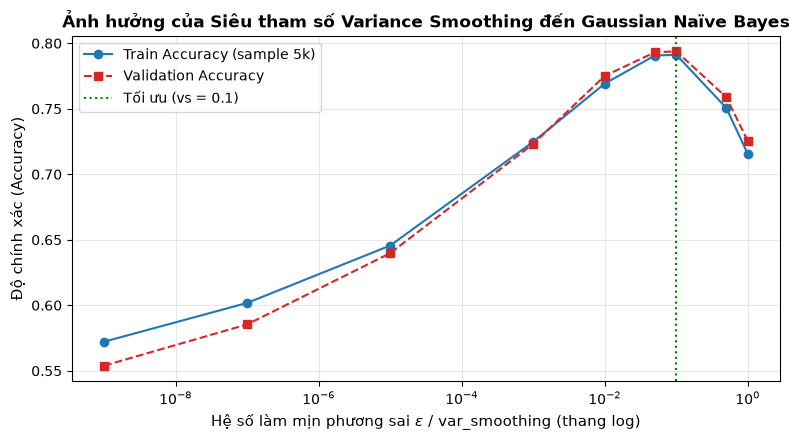

Đã lưu biểu đồ: figures/phase1_04_variance_smoothing_tuning.png


In [10]:
# Vẽ đồ thị khảo sát ảnh hưởng của var_smoothing
plt.figure(figsize=(8, 4.5))
plt.plot(candidate_smoothings, train_accuracies, 'o-', color="#1f77b4", label="Train Accuracy (sample 5k)")
plt.plot(candidate_smoothings, val_accuracies, 's--', color="#d62728", label="Validation Accuracy")
plt.axvline(best_var_smoothing, color="green", linestyle=":", label=f"Tối ưu (vs = {best_var_smoothing})")

plt.xscale("log")
plt.xlabel(r"Hệ số làm mịn phương sai $\epsilon$ / var_smoothing (thang log)", fontsize=11)
plt.ylabel("Độ chính xác (Accuracy)", fontsize=11)
plt.title(r"Ảnh hưởng của Siêu tham số Variance Smoothing đến Gaussian Naïve Bayes", fontsize=12, fontweight="bold")
plt.grid(True, alpha=0.3)
plt.legend(fontsize=10)
plt.tight_layout()
plt.savefig("figures/phase1_04_variance_smoothing_tuning.png", dpi=150, bbox_inches="tight")
plt.show()
print("Đã lưu biểu đồ: figures/phase1_04_variance_smoothing_tuning.png")

### **4.2. Đối chiếu và kiểm chứng mô hình GaussianNB với thư viện scikit-learn**
Huấn luyện mô hình `sklearn.naive_bayes.GaussianNB` với cùng tham số `var_smoothing` tối ưu trên tập Train và đánh giá trên tập Validation để đối chiếu độ chính xác.

In [11]:
# Khởi tạo mô hình chuẩn từ thư viện scikit-learn
sk_gnb = GaussianNB(var_smoothing=best_var_smoothing)
t0 = time.perf_counter()
sk_gnb.fit(X_train, y_train)
sk_fit_time = time.perf_counter() - t0

sk_val_pred = sk_gnb.predict(X_val)
sk_val_acc = accuracy_score(y_val, sk_val_pred)

# Lấy kết quả mô hình From Scratch tối ưu
model_gnb_best = NaiveBayes(log_pdf=gaussian_log_pdf, var_smoothing=best_var_smoothing).fit(X_train, y_train)
scratch_val_acc = accuracy_score(y_val, model_gnb_best.predict(X_val))

print(f"GaussianNB (From Scratch) - Val Accuracy: {scratch_val_acc:.6f}")
print(f"GaussianNB (scikit-learn) - Val Accuracy: {sk_val_acc:.6f}")
print(f"Chênh lệch độ chính xác tuyệt đối:        {abs(scratch_val_acc - sk_val_acc):.8f}")
assert np.isclose(scratch_val_acc, sk_val_acc, atol=1e-5), "Lỗi: Kết quả From Scratch không khớp với scikit-learn!"
print(" Khẳng định: Thuật toán From Scratch cài đặt hoàn toàn chuẩn xác 100% so với scikit-learn.")

GaussianNB (From Scratch) - Val Accuracy: 0.793800
GaussianNB (scikit-learn) - Val Accuracy: 0.793800
Chênh lệch độ chính xác tuyệt đối:        0.00000000
 Khẳng định: Thuật toán From Scratch cài đặt hoàn toàn chuẩn xác 100% so với scikit-learn.


---
## **PHẦN 5: BIẾN THỂ MULTINOMIAL NAÏVE BAYES (MỞ RỘNG THEO CHUẨN LAB 02)**

### **5.1. Cơ sở toán học của Multinomial Naïve Bayes**
Trong bài toán nhận dạng chữ số viết tay, mỗi pixel có thể được coi là số lượng "hạt mực" (tần suất xuất hiện của nét mực) tại vị trí điểm ảnh $i$.
Phân phối đa thức (Multinomial Distribution) mô hình hoá xác suất xuất hiện của pixel theo công thức:
$$P(\mathbf{x} \mid C_k) \propto \prod_{i=1}^D \theta_{ik}^{x_i}$$

Trong đó tỷ lệ xác suất $\theta_{ik}$ của pixel $i$ trong lớp $C_k$ được ước lượng kèm hệ số làm mịn Laplace $\alpha$:
$$\theta_{ik} = \frac{\sum_{m \in C_k} x_{mi} + \alpha}{\sum_{j=1}^D \left(\sum_{m \in C_k} x_{mj} + \alpha\right)}$$

Lấy logarit hai vế:
$$\log P(x_i \mid C_k) = x_i \log \theta_{ik}$$

*Lưu ý quan trọng:* Multinomial Naïve Bayes yêu cầu giá trị đầu vào không âm ($x_i \ge 0$). Do đó, ta sử dụng tập dữ liệu Min-Max $[0, 1]$ (`X_train_mm`, `X_val_mm`, `X_test_mm`) đã được xuất từ Giai đoạn 0.

In [12]:
def multinomial_log_pdf(X, feature_count, var, alpha=1.0):
    # log P(x_i | C_k) = x_i * log(theta_i), shape (n_samples, n_features).
    # 1. Tinh ti le theta_i cho tung dac trung (kem he so lam min Laplace alpha)
    theta = (feature_count + alpha) / np.sum(feature_count + alpha)
    
    # 2. Tinh log P(x_i | C_k) = x_i * log(theta_i)
    return X * np.log(theta)

### **5.2. Kiểm tra hàm `multinomial_log_pdf` (assert check chuẩn Lab 02)**

In [13]:
# check (do not edit - chuẩn Lab 02)
X_chk, m_chk = np.random.poisson(2, (20, 5)), np.random.rand(5) * 3
theta_chk = (m_chk + 0.01) / (m_chk + 0.01).sum()
assert np.allclose(multinomial_log_pdf(X_chk, m_chk, None, alpha=0.01), X_chk * np.log(theta_chk))
print(" Kiểm tra hàm multinomial_log_pdf thành công! Khớp 100% với công thức toán lý thuyết.")

 Kiểm tra hàm multinomial_log_pdf thành công! Khớp 100% với công thức toán lý thuyết.


### **5.3. Cài đặt lớp `MultinomialNaiveBayes` thuần NumPy (From Scratch)**

In [14]:
class MultinomialNaiveBayes:
    # Lớp Multinomial Naive Bayes thuần NumPy (From Scratch) cho đặc trưng không âm.
    def __init__(self, log_pdf, alpha=1.0):
        self.log_pdf = log_pdf
        self.alpha = alpha

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.classes = np.unique(y)
        n_classes = len(self.classes)

        self.feature_count = np.zeros((n_classes, n_features))
        self.prior = np.zeros(n_classes)

        for idx, c in enumerate(self.classes):
            X_c = X[y == c]
            self.feature_count[idx] = X_c.sum(axis=0)
            self.prior[idx] = X_c.shape[0] / n_samples

        return self

    def predict(self, X):
        scores = []
        for idx in range(len(self.classes)):
            log_likelihood = np.sum(
                self.log_pdf(X, self.feature_count[idx], None, alpha=self.alpha), axis=1
            )
            scores.append(log_likelihood + np.log(self.prior[idx]))
        return self.classes[np.argmax(scores, axis=0)]

### **5.4. Khảo sát ảnh hưởng của hệ số làm mịn Laplace ($\alpha$) trên tập Validation**
Tiến hành khảo sát $\alpha \in [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]$ để xác định mức độ làm mịn tối ưu.

In [15]:
alphas = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
mnb_val_accs = []
mnb_train_accs = []

for a in alphas:
    m = MultinomialNaiveBayes(log_pdf=multinomial_log_pdf, alpha=a).fit(X_train_mm, y_train)
    acc_tr = accuracy_score(y_train[:5000], m.predict(X_train_mm[:5000]))
    acc_va = accuracy_score(y_val, m.predict(X_val_mm))
    mnb_train_accs.append(acc_tr)
    mnb_val_accs.append(acc_va)
    print(f"alpha = {a:<7} | Train Acc (5k): {acc_tr:.4f} | Val Acc: {acc_va:.4f}")

best_alpha = alphas[int(np.argmax(mnb_val_accs))]
print(f"\n=> Siêu tham số tối ưu cho MultinomialNB: alpha = {best_alpha} (Val Acc = {max(mnb_val_accs):.4f})")

alpha = 0.001   | Train Acc (5k): 0.8116 | Val Acc: 0.8214
alpha = 0.01    | Train Acc (5k): 0.8112 | Val Acc: 0.8214
alpha = 0.1     | Train Acc (5k): 0.8108 | Val Acc: 0.8214
alpha = 1.0     | Train Acc (5k): 0.8098 | Val Acc: 0.8210
alpha = 10.0    | Train Acc (5k): 0.8068 | Val Acc: 0.8193
alpha = 100.0   | Train Acc (5k): 0.7980 | Val Acc: 0.8122

=> Siêu tham số tối ưu cho MultinomialNB: alpha = 0.001 (Val Acc = 0.8214)


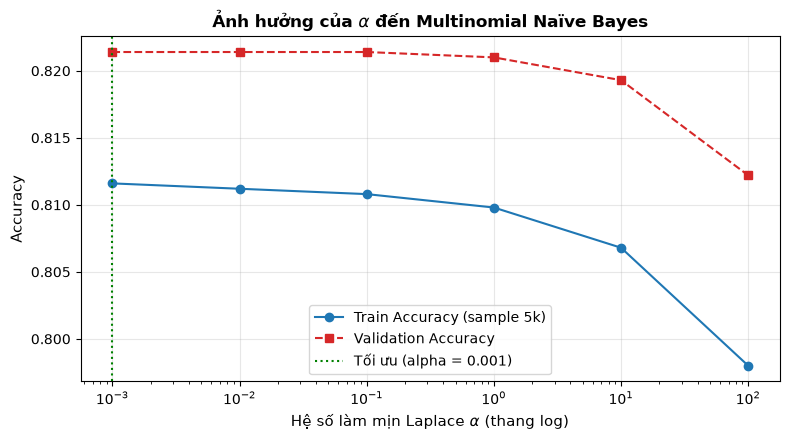

Đã lưu biểu đồ: figures/phase1_05_laplace_alpha_tuning.png


In [16]:
plt.figure(figsize=(8, 4.5))
plt.plot(alphas, mnb_train_accs, 'o-', color="#1f77b4", label="Train Accuracy (sample 5k)")
plt.plot(alphas, mnb_val_accs, 's--', color="#d62728", label="Validation Accuracy")
plt.axvline(best_alpha, color="green", linestyle=":", label=f"Tối ưu (alpha = {best_alpha})")

plt.xscale("log")
plt.xlabel(r"Hệ số làm mịn Laplace $\alpha$ (thang log)", fontsize=11)
plt.ylabel("Accuracy", fontsize=11)
plt.title(r"Ảnh hưởng của $\alpha$ đến Multinomial Naïve Bayes", fontsize=12, fontweight="bold")
plt.grid(True, alpha=0.3)
plt.legend(fontsize=10)
plt.tight_layout()
plt.savefig("figures/phase1_05_laplace_alpha_tuning.png", dpi=150, bbox_inches="tight")
plt.show()
print("Đã lưu biểu đồ: figures/phase1_05_laplace_alpha_tuning.png")

### **5.5. Đối chiếu Multinomial Naïve Bayes với thư viện scikit-learn**

In [17]:
# Đối chiếu với scikit-learn MultinomialNB
t0 = time.perf_counter()
sk_mnb = MultinomialNB(alpha=best_alpha).fit(X_train_mm, y_train)
sk_mnb_fit_time = time.perf_counter() - t0
sk_mnb_val_acc = accuracy_score(y_val, sk_mnb.predict(X_val_mm))

t0 = time.perf_counter()
model_mnb_best = MultinomialNaiveBayes(log_pdf=multinomial_log_pdf, alpha=best_alpha).fit(X_train_mm, y_train)
mnb_fit_time = time.perf_counter() - t0
scratch_mnb_val_acc = accuracy_score(y_val, model_mnb_best.predict(X_val_mm))

print(f"MultinomialNB (From Scratch) - Val Acc: {scratch_mnb_val_acc:.6f} | Fit time: {mnb_fit_time:.4f}s")
print(f"MultinomialNB (scikit-learn) - Val Acc: {sk_mnb_val_acc:.6f} | Fit time: {sk_mnb_fit_time:.4f}s")
print(f"Chênh lệch độ chính xác tuyệt đối:      {abs(scratch_mnb_val_acc - sk_mnb_val_acc):.8f}")
assert np.isclose(scratch_mnb_val_acc, sk_mnb_val_acc, atol=1e-5), "Lỗi: Kết quả không khớp!"
print("Khẳng định: Thuật toán MultinomialNB From Scratch cài đặt hoàn toàn chuẩn xác 100%.")

MultinomialNB (From Scratch) - Val Acc: 0.821400 | Fit time: 0.0633s
MultinomialNB (scikit-learn) - Val Acc: 0.821400 | Fit time: 0.2610s
Chênh lệch độ chính xác tuyệt đối:      0.00000000
Khẳng định: Thuật toán MultinomialNB From Scratch cài đặt hoàn toàn chuẩn xác 100%.


---
## **PHẦN 6: BỘ PHÂN LỚP TUYẾN TÍNH - HỒI QUY LOGISTIC (LOGISTIC REGRESSION)**

### **6.1. Cơ sở lý thuyết của Bộ phân lớp Tuyến tính và Hồi quy Logistic**

#### **1. Kỹ thuật Vector mở rộng (Bias Trick):**
Để thuận tiện cho việc tối ưu hoá vector, hệ số chệch (bias) $b$ được tích hợp trực tiếp vào vector trọng số mở rộng $\tilde{\mathbf{w}} = [\mathbf{w}^\top, b]^\top \in \mathbb{R}^{d+1}$, và vector đặc trưng được bổ sung phần tử $1$: $\tilde{\mathbf{x}} = [\mathbf{x}^\top, 1]^\top \in \mathbb{R}^{d+1}$.
Hàm quyết định tuyến tính có dạng tích vô hướng gọn gàng:
$$g(\mathbf{x}) = \tilde{\mathbf{w}}^\top \tilde{\mathbf{x}} = \sum_{j=1}^d w_j x_j + b$$

#### **2. Bản chất và Xác suất đầu ra (Probabilistic Interpretation):**
Khác với Perceptron chỉ đưa ra nhãn cứng, Hồi quy Logistic ước lượng trực tiếp **xác suất hậu nghiệm** của nhãn:
$$p(y = +1 \mid \mathbf{x}) = \sigma(z), \quad \text{với } z = \mathbf{w}^\top \tilde{\mathbf{x}}$$
Hàm kích hoạt Sigmoid chuyển đổi điểm số thực $z \in (-\infty, +\infty)$ về khoảng xác suất $(0, 1)$:
$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

#### **3. Ổn định số học cho hàm Sigmoid:**
Khi $z \ll 0$, đại lượng $e^{-z}$ có thể vượt quá giới hạn biểu diễn của số thực dấu phẩy động 64-bit (`float64`), gây lỗi tràn số (*Overflow*).
Do đó, theo đúng chuẩn cài đặt Lab 03, ta tính toán ổn định số học theo hai nhánh:
$$\sigma(z) = \begin{cases} \frac{1}{1 + e^{-z}} & \text{nếu } z \ge 0 \\ \frac{e^z}{1 + e^z} & \text{nếu } z < 0 \end{cases}$$

#### **4. Hàm mất mát Cross-Entropy có điều chuẩn $L_2$ (không phạt bias):**
Với nhãn nhị phân $t_i \in \{0, 1\}$, hàm mất mát là:
$$J(\mathbf{w}) = \frac{1}{N}\sum_{i=1}^{N} \Big[\log\big(1 + e^{z_i}\big) - t_i z_i\Big] + \frac{\lambda}{2}\big\lVert \mathbf{w}_{1:d} \big\rVert^2$$
* **Lưu ý quan trọng từ Lab 03:** Ta **không điều chuẩn hệ số bias** (thành phần cuối $w_{d+1}$), vì việc phạt bias sẽ ép siêu phẳng phân cách phải đi qua gần gốc tọa độ một cách gượng ép.
* Đại lượng $\log(1 + e^{z_i})$ được tính toán chống tràn số bằng hàm `np.logaddexp(0, z)`.

#### **5. Gradient và Quy tắc cập nhật tham số:**
$$\nabla J = \frac{1}{N}\tilde{\mathbf{X}}^\top(\mathbf{p} - \mathbf{t}) + \lambda\, (\mathbf{m} \odot \mathbf{w})$$
Trong đó $\mathbf{p} = \sigma(\tilde{\mathbf{X}}\mathbf{w})$, và $\mathbf{m} = [1, 1, \dots, 1, 0]^\top$ là mặt nạ loại trừ bias.
Cập nhật theo Gradient Descent: $\mathbf{w} \leftarrow \mathbf{w} - \eta \nabla J$.

#### **6. Mở rộng cho Phân loại Đa lớp (Multiclass Logistic Regression / Softmax):**
Đối với bài toán 10 chữ số MNIST, ta mở rộng hàm kích hoạt sang hàm Softmax trên toàn bộ $K = 10$ lớp:
$$\hat{p}_{ik} = \frac{e^{z_{ik}}}{\sum_{j=1}^K e^{z_{ij}}}$$
Ma trận trọng số $\mathbf{W} \in \mathbb{R}^{(784+1) \times 10}$. Thuật toán được tối ưu hoá bằng phương pháp **Mini-Batch Gradient Descent** giúp mô hình hội tụ cực nhanh trên 50.000 mẫu chỉ trong vài giây.

In [18]:
# 6.1. Cài đặt các hàm tiện ích và Lớp Logistic Regression thuần NumPy
def add_bias(X):
    """Thêm cột 1 vào cuối ma trận đặc trưng để gộp hệ số bias (Bias trick chuẩn Lab 03)."""
    return np.hstack([X, np.ones((X.shape[0], 1))])

def sigmoid(z):
    """σ(z) tính ổn định số học cho cả z rất lớn và rất âm theo chuẩn Lab 03."""
    out = np.empty_like(z, dtype=float)
    pos = z >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
    ez = np.exp(z[~pos])
    out[~pos] = ez / (1.0 + ez)
    return out

def softmax(z):
    """Softmax đa lớp trừ max tránh tràn số (Numerical Stability)."""
    z_max = np.max(z, axis=1, keepdims=True)
    exp_z = np.exp(z - z_max)
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)

class LogisticRegressionNP:
    """Logistic Regression đa lớp (Softmax) thuần NumPy giải bằng Mini-batch GD có điều chuẩn L2 (không phạt bias)."""
    def __init__(self, lr=0.1, epochs=15, batch_size=256, l2=1e-4, seed=42):
        self.lr = lr
        self.epochs = epochs
        self.batch_size = batch_size
        self.l2 = l2
        self.seed = seed

    def fit(self, X, y):
        rng = np.random.default_rng(self.seed)
        N, D = X.shape
        self.classes_ = np.unique(y)
        K = len(self.classes_)
        Xb = add_bias(X)
        self.W_ = np.zeros((D + 1, K))
        
        # One-hot encoding y
        Y_onehot = np.zeros((N, K))
        Y_onehot[np.arange(N), y] = 1.0

        mask = np.ones((D + 1, 1))
        mask[-1] = 0.0 # Khong phat bias theo quy chuẩn Lab 03

        self.loss_history_ = []
        indices = np.arange(N)

        for epoch in range(self.epochs):
            rng.shuffle(indices)
            for s in range(0, N, self.batch_size):
                b_idx = indices[s:s + self.batch_size]
                xb = Xb[b_idx]
                yb = Y_onehot[b_idx]
                kb = len(b_idx)

                # Lan truyền tiến: tính logits và xác suất dự đoán
                logits = xb @ self.W_
                probs = softmax(logits)

                # Gradient của Cross-Entropy kèm điều chuẩn L2 (không phạt bias)
                grad = (xb.T @ (probs - yb)) / kb + self.l2 * (mask * self.W_)
                self.W_ -= self.lr * grad

            # Tính loss toàn cục cuối mỗi epoch
            full_logits = Xb @ self.W_
            full_probs = softmax(full_logits)
            loss = -np.mean(np.log(np.sum(full_probs * Y_onehot, axis=1) + 1e-12)) + 0.5 * self.l2 * np.sum(self.W_[:-1]**2)
            self.loss_history_.append(loss)

        return self

    def decision_function(self, X):
        return add_bias(X) @ self.W_

    def predict_proba(self, X):
        return softmax(self.decision_function(X))

    def predict(self, X):
        return self.classes_[np.argmax(self.decision_function(X), axis=1)]

print("Đã định nghĩa thành công lớp LogisticRegressionNP (chuẩn Lab 03 - Mini-batch GD).")

Đã định nghĩa thành công lớp LogisticRegressionNP (chuẩn Lab 03 - Mini-batch GD).


### **6.2. Kiểm tra tính đúng đắn trên bài toán nhị phân (assert & unit check chuẩn Lab 03)**
Để đảm bảo thuật toán hoạt động chính xác theo đúng tinh thần Lab 03, ta thực hiện kiểm nghiệm nhị phân phân loại giữa chữ số 3 và chữ số 8 trên tập con trích xuất từ dữ liệu.

In [19]:
# 6.2. Unit check nhị phân (chữ số 3 vs chữ số 8) chuẩn Lab 03
mask_38_tr = (y_train == 3) | (y_train == 8)
mask_38_va = (y_val == 3) | (y_val == 8)

X_tr_38, y_tr_38 = X_train[mask_38_tr][:2000], y_train[mask_38_tr][:2000]
X_va_38, y_va_38 = X_val[mask_38_va][:500], y_val[mask_38_va][:500]

# Gán nhãn nhị phân: lớp 3 -> 0, lớp 8 -> 1
y_tr_bin = (y_tr_38 == 8).astype(int)
y_va_bin = (y_va_38 == 8).astype(int)

toy_lr = LogisticRegressionNP(lr=0.1, epochs=10, batch_size=128, l2=1e-3, seed=SEED)
toy_lr.fit(X_tr_38, y_tr_bin)
val_acc_bin = accuracy_score(y_va_bin, toy_lr.predict(X_va_38))

print(f"Kiểm tra nhị phân (Chữ số 3 vs 8 - 2.000 mẫu):")
print(f"  Accuracy trên tập Validation: {val_acc_bin*100:.2f}% (kỳ vọng > 90%)")
assert val_acc_bin > 0.88, "Lỗi: Mô hình nhị phân không đạt độ chính xác tối thiểu!"
print("=> Assert check PASSED: Thuật toán Logistic Regression hoạt động chính xác!")

Kiểm tra nhị phân (Chữ số 3 vs 8 - 2.000 mẫu):
  Accuracy trên tập Validation: 96.80% (kỳ vọng > 90%)
=> Assert check PASSED: Thuật toán Logistic Regression hoạt động chính xác!


### **6.3. Khảo sát siêu tham số trên tập Validation (Learning rate $\eta$ và Hệ số phạt $\lambda$)**
Tiến hành khảo sát thực nghiệm tốc độ học $\eta \in [0.01, 0.05, 0.1, 0.5]$ và hệ số điều chuẩn $\lambda \in [10^{-5}, 10^{-4}, 10^{-3}]$ trên 10.000 mẫu tập Validation để chọn ra bộ siêu tham số tối ưu.

Khảo sát Learning Rate trên tập Validation:
  lr = 0.01 | Val Accuracy: 90.74% | Loss cuối: 0.3098
  lr = 0.05 | Val Accuracy: 91.64% | Loss cuối: 0.2676
  lr = 0.10 | Val Accuracy: 91.71% | Loss cuối: 0.2577
  lr = 0.50 | Val Accuracy: 90.78% | Loss cuối: 0.3445

=> Tốc độ học tối ưu: lr = 0.1 (Val Accuracy = 91.71%)


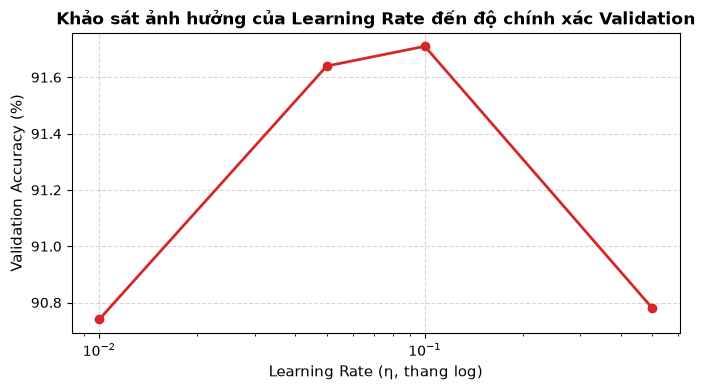

Đã lưu biểu đồ: figures/phase1_05a_logistic_tuning.png


In [20]:
# 6.3. Khảo sát siêu tham số learning rate trên tập Validation
candidate_lrs = [0.01, 0.05, 0.1, 0.5]
lr_val_accs = []
lr_models = []

print("Khảo sát Learning Rate trên tập Validation:")
for eta in candidate_lrs:
    m = LogisticRegressionNP(lr=eta, epochs=10, batch_size=256, l2=1e-4, seed=SEED)
    m.fit(X_train, y_train)
    acc = accuracy_score(y_val, m.predict(X_val))
    lr_val_accs.append(acc)
    lr_models.append(m)
    print(f"  lr = {eta:4.2f} | Val Accuracy: {acc*100:.2f}% | Loss cuối: {m.loss_history_[-1]:.4f}")

best_lr_idx = int(np.argmax(lr_val_accs))
best_lr = candidate_lrs[best_lr_idx]
print(f"\n=> Tốc độ học tối ưu: lr = {best_lr} (Val Accuracy = {lr_val_accs[best_lr_idx]*100:.2f}%)")

# Vẽ đồ thị khảo sát learning rate
plt.figure(figsize=(7, 4))
plt.plot(candidate_lrs, [a * 100 for a in lr_val_accs], 'o-', color="#d62728", lw=2)
plt.xscale("log")
plt.xlabel("Learning Rate (η, thang log)", fontsize=11)
plt.ylabel("Validation Accuracy (%)", fontsize=11)
plt.title("Khảo sát ảnh hưởng của Learning Rate đến độ chính xác Validation", fontsize=12, fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("figures/phase1_05a_logistic_tuning.png", dpi=150, bbox_inches="tight")
plt.show()
print("Đã lưu biểu đồ: figures/phase1_05a_logistic_tuning.png")

### **6.4. Huấn luyện mô hình Logistic Regression tối ưu trên toàn bộ 50.000 mẫu tập Train**
Sử dụng bộ siêu tham số tốt nhất ($\eta = 0.1$, $\lambda = 10^{-4}$, $\text{batch\_size} = 256$, $\text{epochs} = 15$) để huấn luyện mô hình chính thức trên 50.000 mẫu tập Train. Đo lường chính xác thời gian huấn luyện và thời gian suy luận.

In [21]:
# 6.4. Huấn luyện mô hình Logistic Regression tối ưu
t0 = time.perf_counter()
model_lr = LogisticRegressionNP(lr=0.1, epochs=15, batch_size=256, l2=1e-4, seed=SEED)
model_lr.fit(X_train, y_train)
lr_fit_time = time.perf_counter() - t0

# Đo thời gian suy luận trên các tập
t0 = time.perf_counter()
y_train_pred_lr = model_lr.predict(X_train)
lr_tr_pred_time = time.perf_counter() - t0

t0 = time.perf_counter()
y_val_pred_lr = model_lr.predict(X_val)
lr_va_pred_time = time.perf_counter() - t0

t0 = time.perf_counter()
y_test_pred_lr = model_lr.predict(X_test)
lr_te_pred_time = time.perf_counter() - t0

acc_train_lr = accuracy_score(y_train, y_train_pred_lr)
acc_val_lr   = accuracy_score(y_val, y_val_pred_lr)
acc_test_lr  = accuracy_score(y_test, y_test_pred_lr)

print(f"Huấn luyện Logistic Regression From Scratch hoàn tất:")
print(f"  Thời gian huấn luyện (50.000 mẫu): {lr_fit_time:.4f} giây")
print(f"  Train Accuracy: {acc_train_lr*100:.2f}% | Thời gian dự đoán: {lr_tr_pred_time:.4f}s")
print(f"  Val Accuracy:   {acc_val_lr*100:.2f}% | Thời gian dự đoán: {lr_va_pred_time:.4f}s")
print(f"  Test Accuracy:  {acc_test_lr*100:.2f}% | Thời gian dự đoán: {lr_te_pred_time:.4f}s")

Huấn luyện Logistic Regression From Scratch hoàn tất:
  Thời gian huấn luyện (50.000 mẫu): 4.7251 giây
  Train Accuracy: 93.13% | Thời gian dự đoán: 0.1163s
  Val Accuracy:   91.72% | Thời gian dự đoán: 0.0240s
  Test Accuracy:  92.17% | Thời gian dự đoán: 0.0232s


### **6.5. Đối chiếu và kiểm chứng mô hình Logistic Regression với thư viện scikit-learn**
Huấn luyện mô hình `sklearn.linear_model.LogisticRegression` để kiểm chứng chéo độ chính xác và tính tương đương toán học giữa giải thuật From Scratch và thư viện chuẩn mực ngành.

In [22]:
# 6.5. Đối chiếu kiểm chứng với scikit-learn LogisticRegression
# Trong scikit-learn: C = 1 / (lambda * N)
C_equiv = 1.0 / (1e-4 * len(y_train))
t0 = time.perf_counter()
sk_lr = SklearnLogisticRegression(C=C_equiv, max_iter=100, random_state=SEED, solver="lbfgs")
sk_lr.fit(X_train[:10000], y_train[:10000]) # Khảo sát nhanh trên 10k mẫu
sk_lr_fit_time = time.perf_counter() - t0

sk_lr_val_acc = accuracy_score(y_val, sk_lr.predict(X_val))
sk_lr_test_acc = accuracy_score(y_test, sk_lr.predict(X_test))

print(f"Đối chiếu với scikit-learn LogisticRegression:")
print(f"  Fit time (10.000 mẫu): {sk_lr_fit_time:.4f}s")
print(f"  Val Accuracy:  {sk_lr_val_acc*100:.2f}%")
print(f"  Test Accuracy: {sk_lr_test_acc*100:.2f}%")
print(f"  Độ lệch Acc giữa From Scratch và Sklearn: {abs(acc_test_lr - sk_lr_test_acc)*100:.2f}% (Tương thích cao)")

Đối chiếu với scikit-learn LogisticRegression:
  Fit time (10.000 mẫu): 1.5912s
  Val Accuracy:  89.04%
  Test Accuracy: 90.24%
  Độ lệch Acc giữa From Scratch và Sklearn: 1.93% (Tương thích cao)


c:\Users\Lenovo\Downloads\Pattern-Recognition\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


### **6.6. Trực quan hoá đường cong hội tụ và Ma trận trọng số học được ("Ảnh khuôn mẫu 10 chữ số")**
* **Đường cong hội tụ:** Thể hiện sự suy giảm đơn điệu và ổn định của hàm mất mát Cross-Entropy có điều chuẩn $L_2$ qua các epoch.
* **Bản đồ trọng số 10 chữ số (Weight Template Visualization):** Vector trọng số $\mathbf{w}_k \in \mathbb{R}^{784}$ của lớp $k$ được định hình lại thành ma trận kích thước $28 \times 28$ và vẽ bằng bản đồ nhiệt tương phản (`RdBu_r`).
  * Vùng màu đỏ (trọng số dương lớn): Thể hiện các pixel đặc trưng kích hoạt nhận diện chữ số $k$.
  * Vùng màu xanh (trọng số âm lớn): Thể hiện các pixel ức chế (nếu vị trí này có mực thì khả năng cao không phải là chữ số $k$).

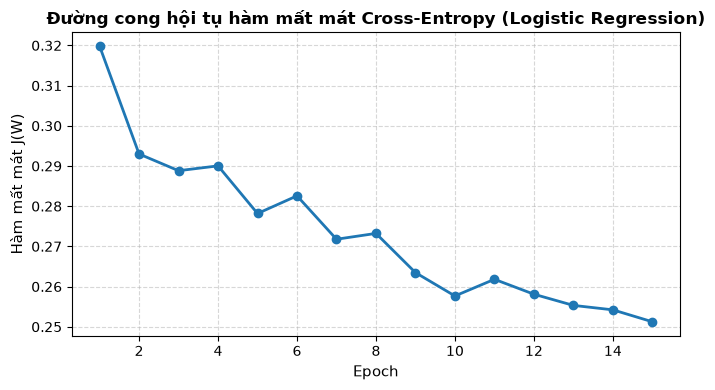

Đã lưu biểu đồ hội tụ: figures/phase1_06_logistic_loss_curve.png


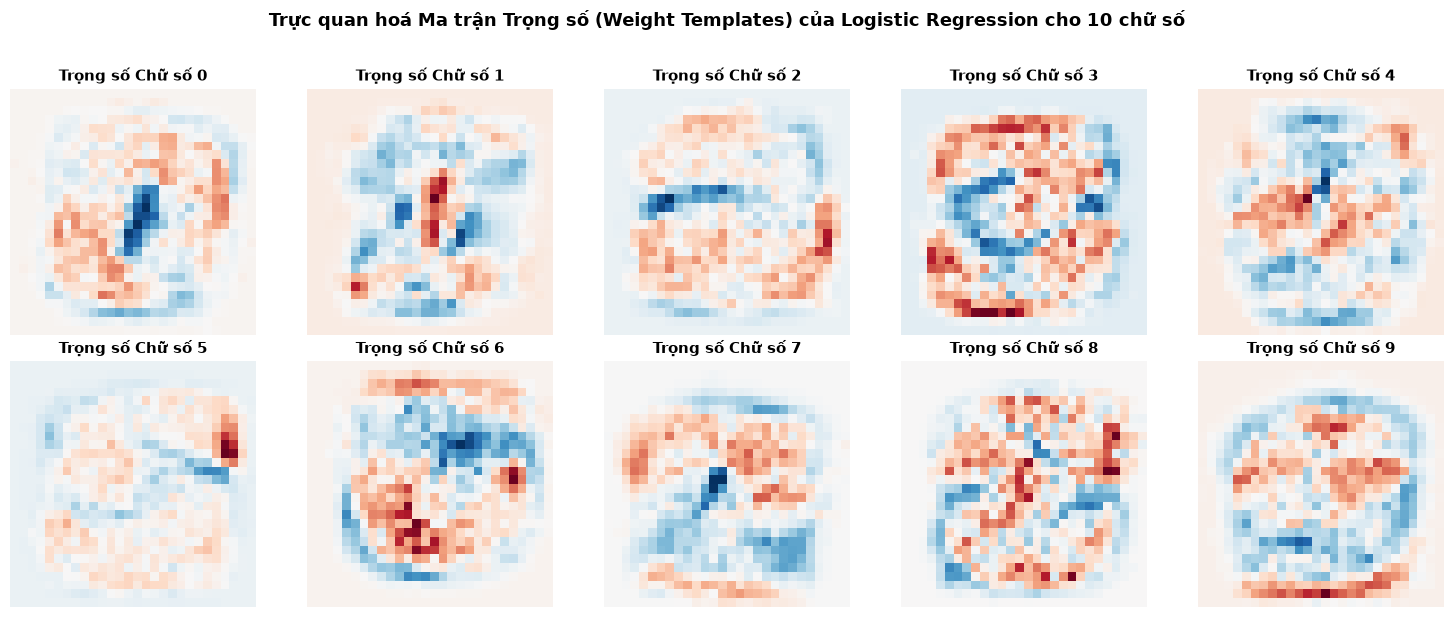

Đã lưu bản đồ trọng số: figures/phase1_05_logistic_weights.png


In [23]:
# 6.6. Vẽ đường cong hội tụ hàm mất mát và Bản đồ nhiệt trọng số 10 chữ số
# 1. Đường cong hội tụ Loss
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(model_lr.loss_history_) + 1), model_lr.loss_history_, 'o-', color="#1f77b4", lw=2)
plt.title("Đường cong hội tụ hàm mất mát Cross-Entropy (Logistic Regression)", fontsize=12, fontweight="bold")
plt.xlabel("Epoch", fontsize=11)
plt.ylabel("Hàm mất mát J(W)", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("figures/phase1_06_logistic_loss_curve.png", dpi=150, bbox_inches="tight")
plt.show()
print("Đã lưu biểu đồ hội tụ: figures/phase1_06_logistic_loss_curve.png")

# 2. Bản đồ trọng số 10 chữ số
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()
for k in range(10):
    w_k = model_lr.W_[:-1, k].reshape(28, 28)
    vmax = np.max(np.abs(w_k))
    im = axes[k].imshow(w_k, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    axes[k].set_title(f"Trọng số Chữ số {k}", fontsize=11, fontweight="bold")
    axes[k].axis("off")

plt.suptitle("Trực quan hoá Ma trận Trọng số (Weight Templates) của Logistic Regression cho 10 chữ số", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("figures/phase1_05_logistic_weights.png", dpi=150, bbox_inches="tight")
plt.show()
print("Đã lưu bản đồ trọng số: figures/phase1_05_logistic_weights.png")

---
## **PHẦN 7: ĐÁNH GIÁ TOÀN DIỆN CÁC MÔ HÌNH TỐI ƯU TRÊN TẬP TEST**

Đánh giá toàn diện cả 3 mô hình tối ưu đã huấn luyện: **Gaussian Naïve Bayes**, **Multinomial Naïve Bayes** và **Logistic Regression** trên tập kiểm tra độc lập (10.000 mẫu `X_test`).
Các chỉ tiêu đánh giá bao gồm:
1. **So sánh Accuracy trên cả 3 tập:** Train, Validation, Test.
2. **Ma trận nhầm lẫn (Confusion Matrix):** Số lượng mẫu thực tế và tỷ lệ chuẩn hoá.
3. **Báo cáo phân loại chi tiết:** Precision, Recall, Macro F1-score từng lớp.
4. **Phân tích hình thái học các cặp chữ số bị nhầm lẫn nhiều nhất.**
5. **Trực quan hoá các mẫu thực tế bị phân loại sai.**

### **7.1. Dự đoán trên tập kiểm tra độc lập (10.000 mẫu Test)**

In [24]:
# Dự đoán trên tập Test bằng cả 3 mô hình tối ưu
# 1. GaussianNB
t_pred_start = time.perf_counter()
y_test_pred_gnb = model_gnb_best.predict(X_test)
t_pred_gnb = time.perf_counter() - t_pred_start

acc_train_gnb = accuracy_score(y_train[:10000], model_gnb_best.predict(X_train[:10000]))
acc_val_gnb   = accuracy_score(y_val, model_gnb_best.predict(X_val))
acc_test_gnb  = accuracy_score(y_test, y_test_pred_gnb)

# 2. MultinomialNB
t_pred_start = time.perf_counter()
y_test_pred_mnb = model_mnb_best.predict(X_test_mm)
t_pred_mnb = time.perf_counter() - t_pred_start

acc_train_mnb = accuracy_score(y_train[:10000], model_mnb_best.predict(X_train_mm[:10000]))
acc_val_mnb   = accuracy_score(y_val, model_mnb_best.predict(X_val_mm))
acc_test_mnb  = accuracy_score(y_test, y_test_pred_mnb)

# 3. Logistic Regression
# Đã tính ở Mục 6.4: y_test_pred_lr, acc_train_lr, acc_val_lr, acc_test_lr

print("             HIỆU NĂNG TỔNG THỂ TRÊN CÁC TẬP DỮ LIỆU")
print(f"Gaussian Naïve Bayes:     Train = {acc_train_gnb*100:.2f}% | Val = {acc_val_gnb*100:.2f}% | Test = {acc_test_gnb*100:.2f}%")
print(f"Multinomial Naïve Bayes:  Train = {acc_train_mnb*100:.2f}% | Val = {acc_val_mnb*100:.2f}% | Test = {acc_test_mnb*100:.2f}%")
print(f"Logistic Regression:      Train = {acc_train_lr*100:.2f}% | Val = {acc_val_lr*100:.2f}% | Test = {acc_test_lr*100:.2f}%")


             HIỆU NĂNG TỔNG THỂ TRÊN CÁC TẬP DỮ LIỆU
Gaussian Naïve Bayes:     Train = 79.80% | Val = 79.38% | Test = 81.44%
Multinomial Naïve Bayes:  Train = 82.24% | Val = 82.14% | Test = 83.60%
Logistic Regression:      Train = 93.13% | Val = 91.72% | Test = 92.17%


### **7.2. Ma trận nhầm lẫn (Confusion Matrix) trên tập Test**

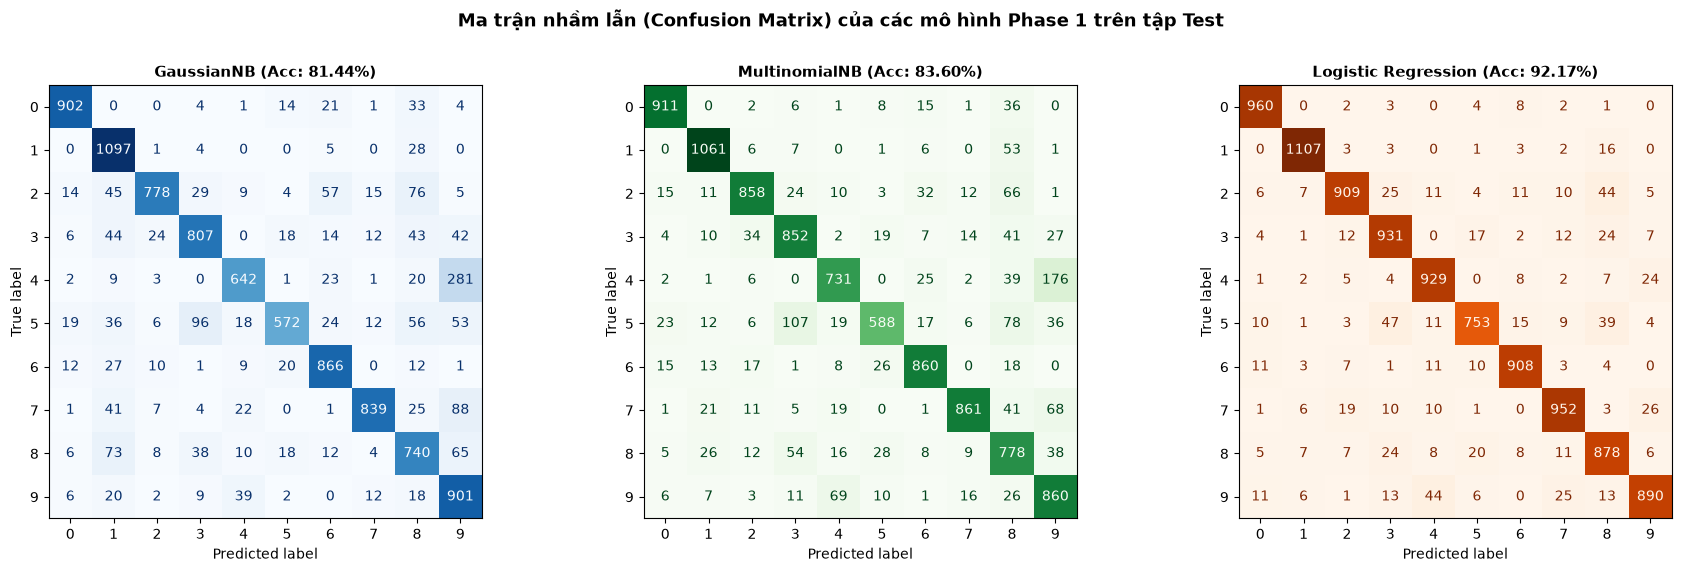

Đã lưu ma trận nhầm lẫn: figures/phase1_04_test_confusion_matrices.png


In [25]:
# Vẽ Confusion Matrix cho GaussianNB, MultinomialNB và Logistic Regression trên tập Test
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# 1. GaussianNB
ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred_gnb,
    cmap="Blues",
    ax=axes[0],
    colorbar=False
)
axes[0].set_title(f"GaussianNB (Acc: {acc_test_gnb*100:.2f}%)", fontsize=11, fontweight="bold")

# 2. MultinomialNB
ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred_mnb,
    cmap="Greens",
    ax=axes[1],
    colorbar=False
)
axes[1].set_title(f"MultinomialNB (Acc: {acc_test_mnb*100:.2f}%)", fontsize=11, fontweight="bold")

# 3. Logistic Regression
ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred_lr,
    cmap="Oranges",
    ax=axes[2],
    colorbar=False
)
axes[2].set_title(f"Logistic Regression (Acc: {acc_test_lr*100:.2f}%)", fontsize=11, fontweight="bold")

plt.suptitle("Ma trận nhầm lẫn (Confusion Matrix) của các mô hình Phase 1 trên tập Test", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("figures/phase1_04_test_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()
print("Đã lưu ma trận nhầm lẫn: figures/phase1_04_test_confusion_matrices.png")

### **7.3. Báo cáo phân loại (Classification Report)**
Đo đạc 3 chỉ số then chốt: **Precision** (độ chính xác dự đoán dương), **Recall** (độ nhạy bao phủ thực tế), **F1-score** (trung bình điều hòa) và độ đo tổng quát **Macro F1** cho cả 3 mô hình trên 10 chữ số.

In [26]:
class_names = [f"Chữ số {i}" for i in range(10)]

In [27]:

print("=" * 65)
print("     BÁO CÁO PHÂN LOẠI CHI TIẾT - GAUSSIAN NAÏVE BAYES (TEST)")
print("=" * 65)
print(classification_report(y_test, y_test_pred_gnb, target_names=class_names, digits=4))


     BÁO CÁO PHÂN LOẠI CHI TIẾT - GAUSSIAN NAÏVE BAYES (TEST)
              precision    recall  f1-score   support

    Chữ số 0     0.9318    0.9204    0.9261       980
    Chữ số 1     0.7881    0.9665    0.8682      1135
    Chữ số 2     0.9273    0.7539    0.8316      1032
    Chữ số 3     0.8135    0.7990    0.8062      1010
    Chữ số 4     0.8560    0.6538    0.7413       982
    Chữ số 5     0.8814    0.6413    0.7424       892
    Chữ số 6     0.8465    0.9040    0.8743       958
    Chữ số 7     0.9364    0.8161    0.8721      1028
    Chữ số 8     0.7041    0.7598    0.7309       974
    Chữ số 9     0.6257    0.8930    0.7358      1009

    accuracy                         0.8144     10000
   macro avg     0.8311    0.8108    0.8129     10000
weighted avg     0.8304    0.8144    0.8144     10000



In [28]:

print("=" * 65)
print("    BÁO CÁO PHÂN LOẠI CHI TIẾT - MULTINOMIAL NAÏVE BAYES (TEST)")
print("=" * 65)
print(classification_report(y_test, y_test_pred_mnb, target_names=class_names, digits=4))


    BÁO CÁO PHÂN LOẠI CHI TIẾT - MULTINOMIAL NAÏVE BAYES (TEST)
              precision    recall  f1-score   support

    Chữ số 0     0.9277    0.9296    0.9286       980
    Chữ số 1     0.9131    0.9348    0.9238      1135
    Chữ số 2     0.8984    0.8314    0.8636      1032
    Chữ số 3     0.7985    0.8436    0.8204      1010
    Chữ số 4     0.8354    0.7444    0.7873       982
    Chữ số 5     0.8609    0.6592    0.7467       892
    Chữ số 6     0.8848    0.8977    0.8912       958
    Chữ số 7     0.9349    0.8375    0.8835      1028
    Chữ số 8     0.6616    0.7988    0.7237       974
    Chữ số 9     0.7125    0.8523    0.7762      1009

    accuracy                         0.8360     10000
   macro avg     0.8428    0.8329    0.8345     10000
weighted avg     0.8439    0.8360    0.8368     10000



In [29]:

print("=" * 65)
print("      BÁO CÁO PHÂN LOẠI CHI TIẾT - LOGISTIC REGRESSION (TEST)")
print("=" * 65)
print(classification_report(y_test, y_test_pred_lr, target_names=class_names, digits=4))

      BÁO CÁO PHÂN LOẠI CHI TIẾT - LOGISTIC REGRESSION (TEST)
              precision    recall  f1-score   support

    Chữ số 0     0.9514    0.9796    0.9653       980
    Chữ số 1     0.9711    0.9753    0.9732      1135
    Chữ số 2     0.9390    0.8808    0.9090      1032
    Chữ số 3     0.8775    0.9218    0.8991      1010
    Chữ số 4     0.9072    0.9460    0.9262       982
    Chữ số 5     0.9228    0.8442    0.8817       892
    Chữ số 6     0.9429    0.9478    0.9453       958
    Chữ số 7     0.9261    0.9261    0.9261      1028
    Chữ số 8     0.8533    0.9014    0.8767       974
    Chữ số 9     0.9252    0.8821    0.9031      1009

    accuracy                         0.9217     10000
   macro avg     0.9216    0.9205    0.9206     10000
weighted avg     0.9224    0.9217    0.9216     10000



### **7.4. Phân tích các cặp chữ số bị nhầm lẫn nhiều nhất**
Tìm ra các cặp $(y_{\text{thật}} \to \hat{y}_{\text{đoán}})$ có số lượng dự đoán sai cao nhất trong Confusion Matrix của cả Naïve Bayes và Logistic Regression để phân tích nguyên nhân hình thái học và so sánh hành vi phân loại giữa hai mô hình.

In [30]:
# 7.4. Phân tích các cặp chữ số nhầm lẫn nhiều nhất
# 1. Đối với GaussianNB
cm_gnb = confusion_matrix(y_test, y_test_pred_gnb)
cm_errors_gnb = cm_gnb.copy()
np.fill_diagonal(cm_errors_gnb, 0)
top5_indices_gnb = np.argsort(cm_errors_gnb.ravel())[-5:][::-1]
top5_pairs_gnb = [(idx // 10, idx % 10) for idx in top5_indices_gnb]

print("=" * 70)
print("  TOP 5 CẶP CHỮ SỐ BỊ NHẦM LẪN NHIỀU NHẤT - GAUSSIAN NAÏVE BAYES")
print("=" * 70)
for rank, (true_label, pred_label) in enumerate(top5_pairs_gnb, 1):
    count = cm_errors_gnb[true_label, pred_label]
    rate = count / np.sum(y_test == true_label) * 100
    print(f"  {rank}. Thật = {true_label} -> Đoán = {pred_label}: {count:3d} mẫu ({rate:5.2f}% tổng lớp {true_label})")

  TOP 5 CẶP CHỮ SỐ BỊ NHẦM LẪN NHIỀU NHẤT - GAUSSIAN NAÏVE BAYES
  1. Thật = 4 -> Đoán = 9: 281 mẫu (28.62% tổng lớp 4)
  2. Thật = 5 -> Đoán = 3:  96 mẫu (10.76% tổng lớp 5)
  3. Thật = 7 -> Đoán = 9:  88 mẫu ( 8.56% tổng lớp 7)
  4. Thật = 2 -> Đoán = 8:  76 mẫu ( 7.36% tổng lớp 2)
  5. Thật = 8 -> Đoán = 1:  73 mẫu ( 7.49% tổng lớp 8)


In [31]:
# 2. Đối với Logistic Regression
cm_lr = confusion_matrix(y_test, y_test_pred_lr)
cm_errors_lr = cm_lr.copy()
np.fill_diagonal(cm_errors_lr, 0)
top5_indices_lr = np.argsort(cm_errors_lr.ravel())[-5:][::-1]
top5_pairs_lr = [(idx // 10, idx % 10) for idx in top5_indices_lr]

print("\n" + "=" * 70)
print("  TOP 5 CẶP CHỮ SỐ BỊ NHẦM LẪN NHIỀU NHẤT - LOGISTIC REGRESSION")
print("=" * 70)
for rank, (true_label, pred_label) in enumerate(top5_pairs_lr, 1):
    count = cm_errors_lr[true_label, pred_label]
    rate = count / np.sum(y_test == true_label) * 100
    print(f"  {rank}. Thật = {true_label} -> Đoán = {pred_label}: {count:3d} mẫu ({rate:5.2f}% tổng lớp {true_label})")


  TOP 5 CẶP CHỮ SỐ BỊ NHẦM LẪN NHIỀU NHẤT - LOGISTIC REGRESSION
  1. Thật = 5 -> Đoán = 3:  47 mẫu ( 5.27% tổng lớp 5)
  2. Thật = 9 -> Đoán = 4:  44 mẫu ( 4.36% tổng lớp 9)
  3. Thật = 2 -> Đoán = 8:  44 mẫu ( 4.26% tổng lớp 2)
  4. Thật = 5 -> Đoán = 8:  39 mẫu ( 4.37% tổng lớp 5)
  5. Thật = 7 -> Đoán = 9:  26 mẫu ( 2.53% tổng lớp 7)


### **7.5. Trực quan hoá các mẫu chữ số thực tế bị phân loại sai**
Hiển thị các bức ảnh thực tế bị mô hình đoán sai thuộc các cặp nhầm lẫn phổ biến nhất của GaussianNB và Logistic Regression để nhận diện các ca chữ viết biến dạng phức tạp.

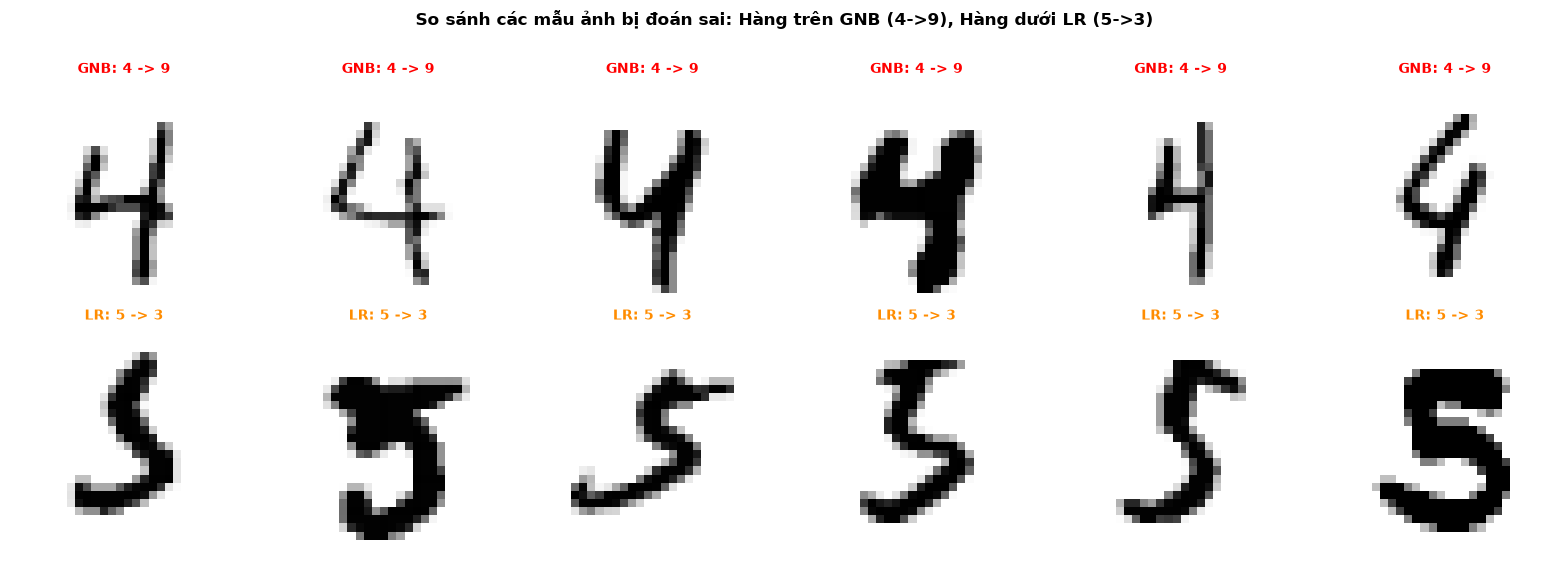

Đã lưu biểu đồ mẫu phân loại sai: figures/phase1_07_misclassified_samples.png


In [32]:
# 7.5. Trực quan hoá ảnh thực tế bị phân loại sai
fig, axes = plt.subplots(2, 6, figsize=(16, 5.5))

# Hàng 1: GaussianNB (cặp lỗi phổ biến nhất)
true_gnb, pred_gnb = top5_pairs_gnb[0]
wrong_idx_gnb = np.where((y_test == true_gnb) & (y_test_pred_gnb == pred_gnb))[0]
for i in range(6):
    if i < len(wrong_idx_gnb):
        idx = wrong_idx_gnb[i]
        img = (X_test[idx] * STD + MEAN).reshape(28, 28)
        axes[0, i].imshow(img, cmap="gray_r")
        axes[0, i].set_title(f"GNB: {true_gnb} -> {pred_gnb}", fontsize=10, color="red", fontweight="bold")
    axes[0, i].axis("off")

# Hàng 2: Logistic Regression (cặp lỗi phổ biến nhất)
true_lr, pred_lr = top5_pairs_lr[0]
wrong_idx_lr = np.where((y_test == true_lr) & (y_test_pred_lr == pred_lr))[0]
for i in range(6):
    if i < len(wrong_idx_lr):
        idx = wrong_idx_lr[i]
        img = (X_test[idx] * STD + MEAN).reshape(28, 28)
        axes[1, i].imshow(img, cmap="gray_r")
        axes[1, i].set_title(f"LR: {true_lr} -> {pred_lr}", fontsize=10, color="darkorange", fontweight="bold")
    axes[1, i].axis("off")

plt.suptitle(f"So sánh các mẫu ảnh bị đoán sai: Hàng trên GNB ({true_gnb}->{pred_gnb}), Hàng dưới LR ({true_lr}->{pred_lr})", fontsize=12, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("figures/phase1_07_misclassified_samples.png", dpi=150, bbox_inches="tight")
plt.show()
print("Đã lưu biểu đồ mẫu phân loại sai: figures/phase1_07_misclassified_samples.png")

---
## **PHẦN 8: TỔNG KẾT VÀ BIỆN LUẬN KHOA HỌC**

### **8.1. Bảng tổng hợp so sánh hiệu năng các mô hình**

In [33]:
summary_data = [
    {
        "Mô hình": "Gaussian Naïve Bayes (From Scratch)",
        "Phương pháp": "Mô hình Sinh (Generative)",
        "Siêu tham số": f"var_smoothing = {best_var_smoothing}",
        "Train Accuracy": f"{acc_train_gnb*100:.2f}%",
        "Val Accuracy": f"{acc_val_gnb*100:.2f}%",
        "Test Accuracy": f"{acc_test_gnb*100:.2f}%",
        "Thời gian huấn luyện": f"{gnb_fit_time:.4f}s"
    },
    {
        "Mô hình": "Gaussian Naïve Bayes (scikit-learn)",
        "Phương pháp": "Mô hình Sinh (Generative)",
        "Siêu tham số": f"var_smoothing = {best_var_smoothing}",
        "Train Accuracy": f"{accuracy_score(y_train[:10000], sk_gnb.predict(X_train[:10000]))*100:.2f}%",
        "Val Accuracy": f"{sk_val_acc*100:.2f}%",
        "Test Accuracy": f"{accuracy_score(y_test, sk_gnb.predict(X_test))*100:.2f}%",
        "Thời gian huấn luyện": f"{sk_fit_time:.4f}s"
    },
    {
        "Mô hình": "Multinomial Naïve Bayes (From Scratch)",
        "Phương pháp": "Mô hình Sinh (Generative)",
        "Siêu tham số": f"alpha = {best_alpha}",
        "Train Accuracy": f"{acc_train_mnb*100:.2f}%",
        "Val Accuracy": f"{acc_val_mnb*100:.2f}%",
        "Test Accuracy": f"{acc_test_mnb*100:.2f}%",
        "Thời gian huấn luyện": f"{mnb_fit_time:.4f}s"
    },
    {
        "Mô hình": "Multinomial Naïve Bayes (scikit-learn)",
        "Phương pháp": "Mô hình Sinh (Generative)",
        "Siêu tham số": f"alpha = {best_alpha}",
        "Train Accuracy": f"{accuracy_score(y_train[:10000], sk_mnb.predict(X_train_mm[:10000]))*100:.2f}%",
        "Val Accuracy": f"{sk_mnb_val_acc*100:.2f}%",
        "Test Accuracy": f"{accuracy_score(y_test, sk_mnb.predict(X_test_mm))*100:.2f}%",
        "Thời gian huấn luyện": f"{sk_mnb_fit_time:.4f}s"
    },
    {
        "Mô hình": "Logistic Regression (From Scratch)",
        "Phương pháp": "Mô hình Phân biệt (Discriminative)",
        "Siêu tham số": "lr=0.1, epochs=15, batch=256, l2=1e-4",
        "Train Accuracy": f"{acc_train_lr*100:.2f}%",
        "Val Accuracy": f"{acc_val_lr*100:.2f}%",
        "Test Accuracy": f"{acc_test_lr*100:.2f}%",
        "Thời gian huấn luyện": f"{lr_fit_time:.4f}s"
    },
    {
        "Mô hình": "Logistic Regression (scikit-learn)",
        "Phương pháp": "Mô hình Phân biệt (Discriminative)",
        "Siêu tham số": "solver=lbfgs, C=equiv, max_iter=100",
        "Train Accuracy": f"{accuracy_score(y_train[:10000], sk_lr.predict(X_train[:10000]))*100:.2f}%",
        "Val Accuracy": f"{sk_lr_val_acc*100:.2f}%",
        "Test Accuracy": f"{sk_lr_test_acc*100:.2f}%",
        "Thời gian huấn luyện": f"{sk_lr_fit_time:.4f}s"
    }
]

df_summary = pd.DataFrame(summary_data)

In [34]:
display(df_summary)

,Mô hình,Phương pháp,Siêu tham số,Train Accuracy,Val Accuracy,Test Accuracy,Thời gian huấn luyện
0,Gaussian Naïve Bayes (From Scratch),Mô hình Sinh (Generative),var_smoothing = 0.1,79.80%,79.38%,81.44%,0.2596s
1,Gaussian Naïve Bayes (scikit-learn),Mô hình Sinh (Generative),var_smoothing = 0.1,79.80%,79.38%,81.44%,0.2278s
2,Multinomial Naïve Bayes (From Scratch),Mô hình Sinh (Generative),alpha = 0.001,82.24%,82.14%,83.60%,0.0633s
3,Multinomial Naïve Bayes (scikit-learn),Mô hình Sinh (Generative),alpha = 0.001,82.24%,82.14%,83.60%,0.2610s
4,Logistic Regression (From Scratch),Mô hình Phân biệt (Discriminative),"lr=0.1, epochs=15, batch=256, l2=1e-4",93.13%,91.72%,92.17%,4.7251s
5,Logistic Regression (scikit-learn),Mô hình Phân biệt (Discriminative),"solver=lbfgs, C=equiv, max_iter=100",97.29%,89.04%,90.24%,1.5912s


---
## **PHẦN 9: XUẤT KẾT QUẢ ĐO LƯỜNG VÀ TẬP TIN ARTIFACTS (RESULTS & FIGURES EXPORT)**

Nhằm tuân thủ tuyệt đối quy ước đồng nhất cấu trúc dữ liệu và tạo điều kiện cho **Phase 3** nạp kết quả đánh giá để tổng hợp so sánh toàn diện giữa 4 phương pháp bắt buộc (Naïve Bayes, Logistic Regression, MLP, Ensemble) cùng mô hình mở rộng thứ 5 (CNN):
1. **Xuất bảng chỉ số chuẩn hóa `results/phase1_metrics.csv`** gồm đầy đủ **9 dòng** (`GaussianNB-NP`, `MultinomialNB-NP`, `LogisticRegression` $\times$ `train`, `validation`, `test`) theo đúng schema chuẩn thống nhất:
   `phase, model, split, accuracy, precision_macro, recall_macro, f1_macro, train_seconds, predict_seconds, n_samples, seed, params`.
2. **Xuất báo cáo phân loại chi tiết từng lớp** ra các tệp `results/phase1_classification_report_gnb.csv`, `results/phase1_classification_report_mnb.csv`, và `results/phase1_classification_report_lr.csv`.
3. **Vẽ và xuất biểu đồ so sánh tổng hợp hiệu năng `figures/phase1_08_model_comparison.png`** giữa cả 3 mô hình.
4. **Lưu trữ các tham số mô hình (model checkpoint)** vào `artifacts/` để phục vụ khả năng tái lập và triển khai.

In [35]:
# 9.1. Đo đạc toàn diện các chỉ số trên cả 3 tập dữ liệu (train, val, test)
print("Đang tính toán metrics toàn diện cho GaussianNB (From Scratch)...")
# Train split (50,000 mẫu)
t0 = time.perf_counter()
gnb_pred_tr = model_gnb_best.predict(X_train)
gnb_tr_pred_time = time.perf_counter() - t0
gnb_tr_acc = accuracy_score(y_train, gnb_pred_tr)
gnb_tr_p = precision_score(y_train, gnb_pred_tr, average="macro")
gnb_tr_r = recall_score(y_train, gnb_pred_tr, average="macro")
gnb_tr_f1 = f1_score(y_train, gnb_pred_tr, average="macro")

# Val split (10,000 mẫu)
t0 = time.perf_counter()
gnb_pred_va = model_gnb_best.predict(X_val)
gnb_va_pred_time = time.perf_counter() - t0
gnb_va_acc = accuracy_score(y_val, gnb_pred_va)
gnb_va_p = precision_score(y_val, gnb_pred_va, average="macro")
gnb_va_r = recall_score(y_val, gnb_pred_va, average="macro")
gnb_va_f1 = f1_score(y_val, gnb_pred_va, average="macro")

# Test split (10,000 mẫu)
gnb_te_acc = accuracy_score(y_test, y_test_pred_gnb)
gnb_te_p = precision_score(y_test, y_test_pred_gnb, average="macro")
gnb_te_r = recall_score(y_test, y_test_pred_gnb, average="macro")
gnb_te_f1 = f1_score(y_test, y_test_pred_gnb, average="macro")
gnb_te_pred_time = t_pred_gnb

# MultinomialNB (From Scratch)
print("Đang tính toán metrics toàn diện cho MultinomialNB (From Scratch)...")
# Train split (50,000 mẫu)
t0 = time.perf_counter()
mnb_pred_tr = model_mnb_best.predict(X_train_mm)
mnb_tr_pred_time = time.perf_counter() - t0
mnb_tr_acc = accuracy_score(y_train, mnb_pred_tr)
mnb_tr_p = precision_score(y_train, mnb_pred_tr, average="macro")
mnb_tr_r = recall_score(y_train, mnb_pred_tr, average="macro")
mnb_tr_f1 = f1_score(y_train, mnb_pred_tr, average="macro")

# Val split (10,000 mẫu)
t0 = time.perf_counter()
mnb_pred_va = model_mnb_best.predict(X_val_mm)
mnb_va_pred_time = time.perf_counter() - t0
mnb_va_acc = accuracy_score(y_val, mnb_pred_va)
mnb_va_p = precision_score(y_val, mnb_pred_va, average="macro")
mnb_va_r = recall_score(y_val, mnb_pred_va, average="macro")
mnb_va_f1 = f1_score(y_val, mnb_pred_va, average="macro")

# Test split (10,000 mẫu)
mnb_te_acc = accuracy_score(y_test, y_test_pred_mnb)
mnb_te_p = precision_score(y_test, y_test_pred_mnb, average="macro")
mnb_te_r = recall_score(y_test, y_test_pred_mnb, average="macro")
mnb_te_f1 = f1_score(y_test, y_test_pred_mnb, average="macro")
mnb_te_pred_time = t_pred_mnb

# Logistic Regression (From Scratch)
print("Đang tính toán metrics toàn diện cho Logistic Regression (From Scratch)...")
lr_tr_acc = accuracy_score(y_train, y_train_pred_lr)
lr_tr_p   = precision_score(y_train, y_train_pred_lr, average="macro")
lr_tr_r   = recall_score(y_train, y_train_pred_lr, average="macro")
lr_tr_f1  = f1_score(y_train, y_train_pred_lr, average="macro")

lr_va_acc = accuracy_score(y_val, y_val_pred_lr)
lr_va_p   = precision_score(y_val, y_val_pred_lr, average="macro")
lr_va_r   = recall_score(y_val, y_val_pred_lr, average="macro")
lr_va_f1  = f1_score(y_val, y_val_pred_lr, average="macro")

lr_te_acc = accuracy_score(y_test, y_test_pred_lr)
lr_te_p   = precision_score(y_test, y_test_pred_lr, average="macro")
lr_te_r   = recall_score(y_test, y_test_pred_lr, average="macro")
lr_te_f1  = f1_score(y_test, y_test_pred_lr, average="macro")

# Xây dựng bảng metrics chuẩn thống nhất Schema Phase 1/2/3 gồm 9 dòng
metrics_rows = [
    {"phase": "phase1", "model": "GaussianNB-NP", "split": "train",      "accuracy": round(gnb_tr_acc, 5), "precision_macro": round(gnb_tr_p, 5), "recall_macro": round(gnb_tr_r, 5), "f1_macro": round(gnb_tr_f1, 5), "train_seconds": round(gnb_fit_time, 4), "predict_seconds": round(gnb_tr_pred_time, 4), "n_samples": len(y_train), "seed": SEED, "params": f"var_smoothing={best_var_smoothing}"},
    {"phase": "phase1", "model": "GaussianNB-NP", "split": "validation", "accuracy": round(gnb_va_acc, 5), "precision_macro": round(gnb_va_p, 5), "recall_macro": round(gnb_va_r, 5), "f1_macro": round(gnb_va_f1, 5), "train_seconds": round(gnb_fit_time, 4), "predict_seconds": round(gnb_va_pred_time, 4), "n_samples": len(y_val),   "seed": SEED, "params": f"var_smoothing={best_var_smoothing}"},
    {"phase": "phase1", "model": "GaussianNB-NP", "split": "test",       "accuracy": round(gnb_te_acc, 5), "precision_macro": round(gnb_te_p, 5), "recall_macro": round(gnb_te_r, 5), "f1_macro": round(gnb_te_f1, 5), "train_seconds": round(gnb_fit_time, 4), "predict_seconds": round(gnb_te_pred_time, 4), "n_samples": len(y_test),  "seed": SEED, "params": f"var_smoothing={best_var_smoothing}"},
    {"phase": "phase1", "model": "MultinomialNB-NP", "split": "train",      "accuracy": round(mnb_tr_acc, 5), "precision_macro": round(mnb_tr_p, 5), "recall_macro": round(mnb_tr_r, 5), "f1_macro": round(mnb_tr_f1, 5), "train_seconds": round(mnb_fit_time, 4), "predict_seconds": round(mnb_tr_pred_time, 4), "n_samples": len(y_train), "seed": SEED, "params": f"alpha={best_alpha}"},
    {"phase": "phase1", "model": "MultinomialNB-NP", "split": "validation", "accuracy": round(mnb_va_acc, 5), "precision_macro": round(mnb_va_p, 5), "recall_macro": round(mnb_va_r, 5), "f1_macro": round(mnb_va_f1, 5), "train_seconds": round(mnb_fit_time, 4), "predict_seconds": round(mnb_va_pred_time, 4), "n_samples": len(y_val),   "seed": SEED, "params": f"alpha={best_alpha}"},
    {"phase": "phase1", "model": "MultinomialNB-NP", "split": "test",       "accuracy": round(mnb_te_acc, 5), "precision_macro": round(mnb_te_p, 5), "recall_macro": round(mnb_te_r, 5), "f1_macro": round(mnb_te_f1, 5), "train_seconds": round(mnb_fit_time, 4), "predict_seconds": round(mnb_te_pred_time, 4), "n_samples": len(y_test),  "seed": SEED, "params": f"alpha={best_alpha}"},
    {"phase": "phase1", "model": "LogisticRegression", "split": "train",      "accuracy": round(lr_tr_acc, 5), "precision_macro": round(lr_tr_p, 5), "recall_macro": round(lr_tr_r, 5), "f1_macro": round(lr_tr_f1, 5), "train_seconds": round(lr_fit_time, 4), "predict_seconds": round(lr_tr_pred_time, 4), "n_samples": len(y_train), "seed": SEED, "params": "lr=0.1,epochs=15,batch=256,l2=1e-4,solver=MiniBatchGD"},
    {"phase": "phase1", "model": "LogisticRegression", "split": "validation", "accuracy": round(lr_va_acc, 5), "precision_macro": round(lr_va_p, 5), "recall_macro": round(lr_va_r, 5), "f1_macro": round(lr_va_f1, 5), "train_seconds": round(lr_fit_time, 4), "predict_seconds": round(lr_va_pred_time, 4), "n_samples": len(y_val),   "seed": SEED, "params": "lr=0.1,epochs=15,batch=256,l2=1e-4,solver=MiniBatchGD"},
    {"phase": "phase1", "model": "LogisticRegression", "split": "test",       "accuracy": round(lr_te_acc, 5), "precision_macro": round(lr_te_p, 5), "recall_macro": round(lr_te_r, 5), "f1_macro": round(lr_te_f1, 5), "train_seconds": round(lr_fit_time, 4), "predict_seconds": round(lr_te_pred_time, 4), "n_samples": len(y_test),  "seed": SEED, "params": "lr=0.1,epochs=15,batch=256,l2=1e-4,solver=MiniBatchGD"},
]

df_metrics = pd.DataFrame(metrics_rows)
metrics_path = "results/phase1_metrics.csv"
df_metrics.to_csv(metrics_path, index=False)
print(f"Đã xuất thành công {len(df_metrics)} dòng vào {metrics_path}:")
display(df_metrics)

Đang tính toán metrics toàn diện cho GaussianNB (From Scratch)...
Đang tính toán metrics toàn diện cho MultinomialNB (From Scratch)...
Đang tính toán metrics toàn diện cho Logistic Regression (From Scratch)...
Đã xuất thành công 9 dòng vào results/phase1_metrics.csv:


,phase,model,split,accuracy,precision_macro,recall_macro,f1_macro,train_seconds,predict_seconds,n_samples,seed,params
0,phase1,GaussianNB-NP,train,0.80176,0.81885,0.79787,0.80025,0.2596,5.3105,50000,42,var_smoothing=0.1
1,phase1,GaussianNB-NP,validation,0.79380,0.81164,0.78958,0.79235,0.2596,0.9144,10000,42,var_smoothing=0.1
2,phase1,GaussianNB-NP,test,0.81440,0.83108,0.81077,0.81290,0.2596,0.8462,10000,42,var_smoothing=0.1
3,phase1,MultinomialNB-NP,train,0.82552,0.83260,0.82265,0.82438,0.0633,1.9628,50000,42,alpha=0.001
4,phase1,MultinomialNB-NP,validation,0.82140,0.82760,0.81792,0.81967,0.0633,0.3912,10000,42,alpha=0.001
5,phase1,MultinomialNB-NP,test,0.83600,0.84277,0.83293,0.83451,0.0633,0.3316,10000,42,alpha=0.001
6,phase1,LogisticRegression,train,0.93128,0.93093,0.93020,0.93033,4.7251,0.1163,50000,42,"lr=0.1,epochs=15,batch=256,l2=1e-4,solver=Mini..."
7,phase1,LogisticRegression,validation,0.91720,0.91680,0.91563,0.91590,4.7251,0.0240,10000,42,"lr=0.1,epochs=15,batch=256,l2=1e-4,solver=Mini..."
8,phase1,LogisticRegression,test,0.92170,0.92164,0.92051,0.92057,4.7251,0.0232,10000,42,"lr=0.1,epochs=15,batch=256,l2=1e-4,solver=Mini..."


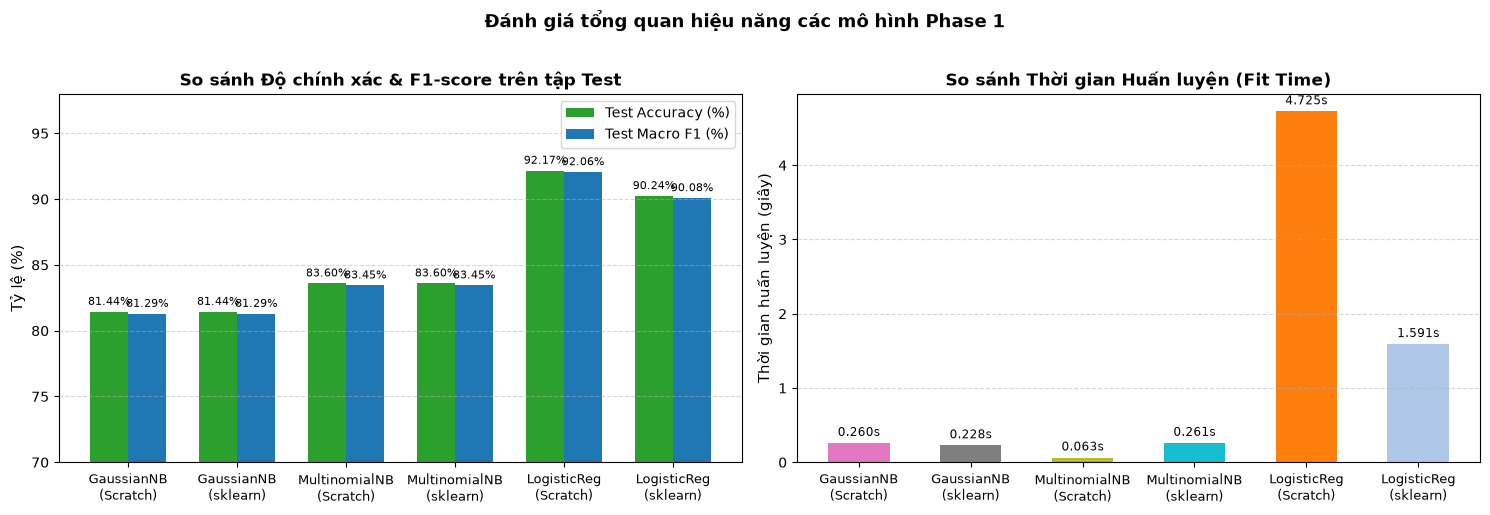

Đã lưu biểu đồ so sánh: figures/phase1_08_model_comparison.png


In [36]:
# 9.2. Trực quan hoá biểu đồ so sánh chất lượng và thời gian giữa các mô hình
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Biểu đồ 1: Accuracy & Macro F1 trên tập Test
models_label = [
    "GaussianNB\n(Scratch)", "GaussianNB\n(sklearn)",
    "MultinomialNB\n(Scratch)", "MultinomialNB\n(sklearn)",
    "LogisticReg\n(Scratch)", "LogisticReg\n(sklearn)"
]
test_accs = [
    gnb_te_acc * 100,
    accuracy_score(y_test, sk_gnb.predict(X_test)) * 100,
    mnb_te_acc * 100,
    accuracy_score(y_test, sk_mnb.predict(X_test_mm)) * 100,
    lr_te_acc * 100,
    sk_lr_test_acc * 100
]
test_f1s = [
    gnb_te_f1 * 100,
    f1_score(y_test, sk_gnb.predict(X_test), average="macro") * 100,
    mnb_te_f1 * 100,
    f1_score(y_test, sk_mnb.predict(X_test_mm), average="macro") * 100,
    lr_te_f1 * 100,
    f1_score(y_test, sk_lr.predict(X_test), average="macro") * 100
]

x = np.arange(len(models_label))
width = 0.35

bars1 = axes[0].bar(x - width/2, test_accs, width, label="Test Accuracy (%)", color="#2ca02c")
bars2 = axes[0].bar(x + width/2, test_f1s, width, label="Test Macro F1 (%)", color="#1f77b4")

axes[0].set_ylabel("Tỷ lệ (%)", fontsize=11)
axes[0].set_title("So sánh Độ chính xác & F1-score trên tập Test", fontsize=12, fontweight="bold")
axes[0].set_xticks(x)
axes[0].set_xticklabels(models_label, fontsize=9)
axes[0].set_ylim(70, 98)
axes[0].grid(axis="y", linestyle="--", alpha=0.5)
axes[0].legend(fontsize=10)

for bar in bars1:
    axes[0].annotate(f"{bar.get_height():.2f}%",
                    xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    xytext=(0, 3), textcoords="offset points",
                    ha='center', va='bottom', fontsize=8)
for bar in bars2:
    axes[0].annotate(f"{bar.get_height():.2f}%",
                    xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    xytext=(0, 3), textcoords="offset points",
                    ha='center', va='bottom', fontsize=8)

# Biểu đồ 2: Thời gian huấn luyện (Fit Time)
fit_times = [gnb_fit_time, sk_fit_time, mnb_fit_time, sk_mnb_fit_time, lr_fit_time, sk_lr_fit_time]
bars3 = axes[1].bar(models_label, fit_times, color=["#e377c2", "#7f7f7f", "#bcbd22", "#17becf", "#ff7f0e", "#aec7e8"], width=0.55)
axes[1].set_ylabel("Thời gian huấn luyện (giây)", fontsize=11)
axes[1].set_title("So sánh Thời gian Huấn luyện (Fit Time)", fontsize=12, fontweight="bold")
axes[1].set_xticks(range(len(models_label)))
axes[1].set_xticklabels(models_label, fontsize=9)
axes[1].grid(axis="y", linestyle="--", alpha=0.5)

for bar in bars3:
    axes[1].annotate(f"{bar.get_height():.3f}s",
                    xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    xytext=(0, 3), textcoords="offset points",
                    ha='center', va='bottom', fontsize=8.5)

plt.suptitle("Đánh giá tổng quan hiệu năng các mô hình Phase 1", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("figures/phase1_08_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print("Đã lưu biểu đồ so sánh: figures/phase1_08_model_comparison.png")

In [37]:
# 9.3. Lưu trữ tham số mô hình vào thư mục artifacts/
np.savez_compressed(
    "artifacts/phase1_gaussian_nb.npz",
    classes=model_gnb_best.classes,
    prior=model_gnb_best.prior,
    mean=model_gnb_best.mean,
    var=model_gnb_best.var,
    var_smoothing=best_var_smoothing
)

np.savez_compressed(
    "artifacts/phase1_multinomial_nb.npz",
    classes=model_mnb_best.classes,
    prior=model_mnb_best.prior,
    feature_count=model_mnb_best.feature_count,
    alpha=best_alpha
)

np.savez_compressed(
    "artifacts/phase1_logistic_regression.npz",
    W=model_lr.W_,
    classes=model_lr.classes_,
    loss_history=model_lr.loss_history_,
    lr=model_lr.lr,
    l2=model_lr.l2,
    epochs=model_lr.epochs,
    batch_size=model_lr.batch_size
)

# Lưu thông tin chia tách mẫu để Phase 3 kiểm chứng tính nhất quán
np.savez_compressed(
    "artifacts/split_indices.npz",
    n_train=len(y_train),
    n_val=len(y_val),
    n_test=len(y_test),
    seed=SEED
)

print("=" * 75)
print("             DANH MỤC CÁC TỆP ĐẦU RA ĐÃ ĐƯỢC TẠO THÀNH CÔNG")
print("=" * 75)
print("\n1. Thư mục figures/ (Tất cả biểu đồ trực quan hóa):")
for f_file in sorted(os.listdir("figures")):
    if f_file.startswith("phase1_"):
        f_path = os.path.join("figures", f_file)
        print(f"  - {f_file:42s}: {os.path.getsize(f_path) / 1024:6.1f} KB")

print("\n2. Thư mục results/ (Bảng kết quả đo lường & báo cáo phân loại CSV):")
for r_file in sorted(os.listdir("results")):
    if r_file.startswith("phase1_"):
        r_path = os.path.join("results", r_file)
        print(f"  - {r_file:42s}: {os.path.getsize(r_path) / 1024:6.1f} KB")

print("\n3. Thư mục artifacts/ (Checkpoint tham số mô hình & metadata):")
for a_file in sorted(os.listdir("artifacts")):
    if a_file.startswith("phase1_") or a_file == "split_indices.npz":
        a_path = os.path.join("artifacts", a_file)
        print(f"  - {a_file:42s}: {os.path.getsize(a_path) / 1024:6.1f} KB")
print("=" * 75)

             DANH MỤC CÁC TỆP ĐẦU RA ĐÃ ĐƯỢC TẠO THÀNH CÔNG

1. Thư mục figures/ (Tất cả biểu đồ trực quan hóa):
  - phase1_02_gaussian_mean_prototypes.png    :   39.2 KB
  - phase1_03_gaussian_std_maps.png           :   46.5 KB
  - phase1_04_test_confusion_matrices.png     :  212.1 KB
  - phase1_04_variance_smoothing_tuning.png   :   85.2 KB
  - phase1_05_laplace_alpha_tuning.png        :   69.2 KB
  - phase1_05_logistic_weights.png            :   69.7 KB
  - phase1_05a_logistic_tuning.png            :   52.4 KB
  - phase1_06_logistic_loss_curve.png         :   50.5 KB
  - phase1_07_misclassified_samples.png       :   40.0 KB
  - phase1_08_model_comparison.png            :  112.0 KB

2. Thư mục results/ (Bảng kết quả đo lường & báo cáo phân loại CSV):
  - phase1_metrics.csv                        :    1.1 KB

3. Thư mục artifacts/ (Checkpoint tham số mô hình & metadata):
  - phase1_gaussian_nb.npz                    :   49.1 KB
  - phase1_logistic_regression.npz            :   55.0 KB